# 🎵 Proyecto Integrador: Machine Learning — Pre-Entrega y Entrega Final

**Programa:** Talento Tech — Especialización en Machine Learning (Nivel Avanzado)  
**Comisión:** #26240  
**Docente:** Maximiliano Torreblanca  
**Tutora:** Agustina Digiesi  
**Estudiante:** Matías Hernández  

---

### 🎯 Alcance Integral del Cuaderno
Este notebook da continuidad directa al trabajo de la Pre-Entrega cumpliendo con las dos instancias del Proyecto Integrador:

- **Parte A — Pre-Entrega (Secciones 1 a 6):** Definición del problema (*Hit Prediction* en Spotify), Análisis Exploratorio de Datos (EDA), limpieza de duplicados/nulos/outliers, ingeniería básica de variables (`is_hit`), partición estratificada 80/20 y escalado sin fuga de información (*Data Leakage*).
- **Parte B — Entrega Final (Secciones 7 a 14):** Experimentación multimodelo supervisada (*Baseline*, Regresión Logística, KNN, Árbol de Decisión y Random Forest), validación cruzada estratificada (*Stratified K-Fold*), optimización sistemática con `GridSearchCV` y `Pipeline`, experimento controlado *Solo Audio vs. Audio + Género* con `ColumnTransformer`, visualizaciones comparativas, análisis de aciertos/errores sobre canciones reales, segmentación no supervisada con **K-Means**, conclusiones estratégicas y Anexo Final.

## 1. Selección y Justificación del Dataset

### 1.1 Contexto del Problema y Relevancia en la Industria
En la industria contemporánea de streaming digital, plataformas como **Spotify** gestionan catálogos que superan los 100 millones de canciones, recibiendo más de 100.000 nuevos lanzamientos diarios. En este ecosistema saturado de información, determinar qué factores acústicos y sensoriales incrementan la probabilidad de que una composición musical trascienda y se convierta en un éxito comercial (*Hit*) es una ventaja estratégica decisiva tanto para sellos discográficos como para artistas independientes y curadores de playlists.

### 1.2 Definición del Problema de Machine Learning
- **Paradigma:** Aprendizaje Supervisado — **Clasificación Binaria**.
- **Variable Objetivo (`target`):** Se creará la variable `is_hit` $\in \{0, 1\}$, basada en el índice oficial de popularidad de Spotify (`popularity > 50`).
  - `1` (**Hit**): Canción de alto impacto comercial y popularidad masiva.
  - `0` (**No Hit / Nicho**): Canción con desempeño estándar, de nicho o menor visibilidad.
- **Variables Predictoras (`features`):** Atributos cuantitativos de audio extraídos mediante la API de Spotify (bailabilidad, nivel de energía, volumen sonoro, valencia emocional, tempo, tempo rítmico, etc.).

### 1.3 Origen del Dataset y Justificación Técnica de la Elección
- **Fuente de datos:** Kaggle — [Spotify Tracks Dataset](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset) recopilado por Maharshi Pandya a través de la API oficial de Spotify for Developers.
- **Justificación de su elección:**
  1. **Estructura y Escala Óptimas:** Cuenta con aproximadamente 114.000 registros y 21 atributos tabulares. Posee una escala suficientemente amplia para permitir que los modelos aprendan patrones no triviales sin generar cuellos de botella de memoria en entornos como Google Colab.
  2. **Riqueza de Atributos Continuos Estandarizados:** Gran parte de sus características sensoriales (`danceability`, `energy`, `valence`, `speechiness`) se encuentran acotadas en el intervalo $[0.0, 1.0]$, mientras que otras (`duration_ms`, `tempo`, `loudness`) están en escalas diferentes. Esto permite demostrar la necesidad teórica y práctica del preprocesamiento y escalado de datos (evitando distorsiones en algoritmos sensibles a la distancia como **KNN**, abordado en la Clase 8).
  3. **Alineación Pedagógica:** Cumple con la sugerencia docente de utilizar conjuntos de datos moderados en complejidad que permitan centrarse en la rigurosidad del flujo analítico y la justificación técnica de cada decisión.

### 1.4 Diccionario de Variables

| Variable | Tipo de Dato | Descripción | Rango / Valores |
| :--- | :---: | :--- | :---: |
| `track_id` | Alfanumérico (`str`) | Identificador único de la pista en Spotify | Texto ID |
| `artists` | Categórico (`str`) | Nombre del artista o artistas colaboradores | Texto |
| `album_name` | Categórico (`str`) | Nombre del álbum en el que aparece la pista | Texto |
| `track_name` | Categórico (`str`) | Nombre o título de la canción | Texto |
| `popularity` | Numérico Discreto (`int`) | Medida de popularidad calculada por el algoritmo de Spotify | $0$ a $100$ |
| `duration_ms` | Numérico Continuo (`int`) | Duración de la pista musical expresada en milisegundos | $> 0$ ms |
| `explicit` | Booleano (`bool`) | Indica si la pista contiene líricas con lenguaje explícito | `True` / `False` |
| `danceability` | Numérico Continuo (`float`) | Qué tan adecuada es la pista para bailar según ritmo y estabilidad | $0.0$ a $1.0$ |
| `energy` | Numérico Continuo (`float`) | Medida perceptual de intensidad, velocidad y volumen | $0.0$ a $1.0$ |
| `key` | Categórico / Discreto (`int`) | Tonalidad armónica de la pista (Notación Pitch Class, 0=Do, 1=Do#, etc.) | $0$ a $11$ |
| `loudness` | Numérico Continuo (`float`) | Volumen sonoro general promedio ponderado en decibelios (dB) | $-60$ a $0$ dB |
| `mode` | Binario (`int`) | Modalidad de la pista (Escala Mayor = 1, Menor = 0) | $0$ o $1$ |
| `speechiness` | Numérico Continuo (`float`) | Presencia relativa de palabras habladas / vocales | $0.0$ a $1.0$ |
| `acousticness` | Numérico Continuo (`float`) | Medida de confianza de si la pista fue grabada con instrumentos acústicos | $0.0$ a $1.0$ |
| `instrumentalness` | Numérico Continuo (`float`) | Predicción de ausencia de contenido vocal (valores > 0.5 sugieren instrumental) | $0.0$ a $1.0$ |
| `liveness` | Numérico Continuo (`float`) | Probabilidad de que la grabación se haya realizado en vivo con público | $0.0$ a $1.0$ |
| `valence` | Numérico Continuo (`float`) | Positividad o estado de ánimo musical (1.0 = eufórico/feliz, 0.0 = triste/sombrío) | $0.0$ a $1.0$ |
| `tempo` | Numérico Continuo (`float`) | Tempo o velocidad musical estimada en pulsos por minuto (BPM) | BPM ($>0$) |
| `time_signature` | Discreto (`int`) | Compás métrico musical estimado (3/4, 4/4, etc.) | $3$ a $7$ |
| `track_genre` | Categórico (`str`) | Género musical primario al que pertenece la pista (114 géneros) | Texto |

In [1]:
# =============================================================================
# 1. CONFIGURACIÓN DEL ENTORNO Y CARGA DE LIBRERÍAS
# =============================================================================

# Instalación y carga de kagglehub para descarga automatizada y reproducible
try:
    import kagglehub
    from kagglehub import KaggleDatasetAdapter
except ImportError:
    !pip install -q kagglehub
    import kagglehub
    from kagglehub import KaggleDatasetAdapter

# Librerías para manipulación y computación numérica
import pandas as pd
import numpy as np

# Librerías para visualización de datos y estilos
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías de Scikit-Learn para preprocesamiento y partición
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Filtro de advertencias y configuración de visualización
import warnings
warnings.filterwarnings('ignore')

# Configuración estética de gráficos y visualización de DataFrames
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)

print("✅ Entorno y librerías inicializadas correctamente.")

C:\Users\n_e_o\IA\Talento Tech - ML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Entorno y librerías inicializadas correctamente.


In [2]:
# =============================================================================
# 2. CARGA REPRODUCIBLE DEL DATASET DE SPOTIFY
# =============================================================================

import os

ruta_kaggle = "maharshipandya/-spotify-tracks-dataset"
nombre_archivo = "dataset.csv"

print(f"[*] Descargando y cargando dataset '{ruta_kaggle}'...")

df = None
rutas_locales = [
    nombre_archivo,
    os.path.join("03_recursos", "datasets", nombre_archivo),
    os.path.join("..", "..", "03_recursos", "datasets", nombre_archivo),
]

try:
    # Método directo mediante KaggleHub
    df = kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        ruta_kaggle,
        nombre_archivo
    )
    print("✅ Dataset cargado exitosamente desde KaggleHub.")
except Exception as e:
    print(f"[!] Aviso al usar dataset_load ({e}). Probando rutas locales o descarga directa...")
    for ruta in rutas_locales:
        if os.path.exists(ruta):
            df = pd.read_csv(ruta)
            print(f"✅ Dataset cargado exitosamente desde ruta local: {ruta}")
            break
    if df is None:
        carpeta_cache = kagglehub.dataset_download(ruta_kaggle)
        df = pd.read_csv(os.path.join(carpeta_cache, nombre_archivo))
        print("✅ Dataset cargado exitosamente vía kagglehub.dataset_download.")

# Comprobación dimensional preliminar
print(f"\nDimensiones iniciales del dataset:")
print(f" - Filas (canciones): {df.shape[0]:,}")
print(f" - Columnas (atributos): {df.shape[1]}")

# Visualizamos las primeras 5 observaciones
display(df.head())

[*] Descargando y cargando dataset 'maharshipandya/-spotify-tracks-dataset'...


  0%|          | 0.00/8.17M [00:00<?, ?B/s]

 12%|█▏        | 1.00M/8.17M [00:00<00:06, 1.25MB/s]

 24%|██▍       | 2.00M/8.17M [00:00<00:02, 2.49MB/s]

 49%|████▉     | 4.00M/8.17M [00:01<00:00, 5.30MB/s]

 86%|████████▌ | 7.00M/8.17M [00:01<00:00, 10.0MB/s]

100%|██████████| 8.17M/8.17M [00:01<00:00, 6.89MB/s]

Extracting zip of dataset.csv...


✅ Dataset cargado exitosamente desde KaggleHub.

Dimensiones iniciales del dataset:
 - Filas (canciones): 114,000
 - Columnas (atributos): 21


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,1.0100e-06,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,5.5600e-06,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.0000e+00,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,7.0700e-05,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.0000e+00,0.0829,0.167,119.949,4,acoustic


## 2. Análisis Exploratorio de Datos (EDA)

El objetivo fundamental de esta fase es inspeccionar la estructura interna del dataset, evaluar la calidad de los registros, detectar valores faltantes o inconsistencias, examinar la distribución de las variables individuales (univariado) e identificar asociaciones y correlaciones entre atributos (bivariado y multivariado).

Este diagnóstico orientará con fundamento técnico las decisiones que tomaremos en las etapas posteriores de limpieza, ingeniería de variables y escalado.

In [3]:
# =============================================================================
# 2.1 ESTRUCTURA GENERAL, TIPOS DE DATOS Y VALORES NULOS
# =============================================================================

print("--- INFORMACIÓN ESTRUCTURAL DEL DATAFRAME ---")
df.info()

print("\n--- RESUMEN DE VALORES NULOS POR COLUMNA ---")
nulos_conteo = df.isnull().sum()
nulos_porc = (df.isnull().sum() / len(df)) * 100
tabla_nulos = pd.DataFrame({
    'Valores Nulos': nulos_conteo,
    'Porcentaje (%)': nulos_porc
})
# Mostramos únicamente las columnas que presenten nulos (o las primeras si no hay)
display(tabla_nulos[tabla_nulos['Valores Nulos'] > 0])

print("\n--- REGISTROS DUPLICADOS PRELIMINARES ---")
print(f"Filas completamente duplicadas: {df.duplicated().sum():,}")
if 'track_id' in df.columns:
    print(f"IDs de canciones duplicadas (track_id): {df['track_id'].duplicated().sum():,}")

--- INFORMACIÓN ESTRUCTURAL DEL DATAFRAME ---
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null

,Valores Nulos,Porcentaje (%)
artists,1,0.0009
album_name,1,0.0009
track_name,1,0.0009



--- REGISTROS DUPLICADOS PRELIMINARES ---


Filas completamente duplicadas: 0
IDs de canciones duplicadas (track_id): 24,259


In [4]:
# =============================================================================
# 2.2 ESTADÍSTICAS DESCRIPTIVAS DE LAS VARIABLES NUMÉRICAS
# =============================================================================

# Excluimos identificadores categóricos y vemos medidas de tendencia central y dispersión
cols_numericas = df.select_dtypes(include=[np.number]).columns.tolist()
display(df[cols_numericas].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.5000,32909.1097,0.000,28499.7500,5.7000e+04,85499.2500,1.1400e+05
popularity,114000.0,33.2385,22.3051,0.000,17.0000,3.5000e+01,50.0000,1.0000e+02
duration_ms,114000.0,228029.1531,107297.7126,0.000,174066.0000,2.1291e+05,261506.0000,5.2373e+06
danceability,114000.0,0.5668,0.1735,0.000,0.4560,5.8000e-01,0.6950,9.8500e-01
energy,114000.0,0.6414,0.2515,0.000,0.4720,6.8500e-01,0.8540,1.0000e+00
key,114000.0,5.3091,3.5600,0.000,2.0000,5.0000e+00,8.0000,1.1000e+01
loudness,114000.0,-8.2590,5.0293,-49.531,-10.0130,-7.0040e+00,-5.0030,4.5320e+00
mode,114000.0,0.6376,0.4807,0.000,0.0000,1.0000e+00,1.0000,1.0000e+00
speechiness,114000.0,0.0847,0.1057,0.000,0.0359,4.8900e-02,0.0845,9.6500e-01
acousticness,114000.0,0.3149,0.3325,0.000,0.0169,1.6900e-01,0.5980,9.9600e-01


### 🔍 Observaciones Propias: Estructura Inicial y Calidad de Datos
1. **Completitud del Dataset:** La presencia de valores nulos es prácticamente marginal (menos de 5 registros en columnas de texto como `artists`, `album_name` y `track_name`), representando menos del $0.005\%$ del total. Esto permitirá una resolución sencilla mediante eliminación directa sin pérdida estadística significativa.
2. **Duplicados:** Se detectan tanto duplicados exactos de filas como duplicados a nivel de `track_id` (debido a canciones que figuran en múltiples recopilatorios o playlists de géneros distintos). Deberán ser saneados en la fase de limpieza para evitar sesgos en el entrenamiento.
3. **Anomalías en Mínimos y Máximos:**
   - En `duration_ms`, el valor mínimo registrado es $0$ ms, lo cual es físicamente imposible para una pista musical grabada y denota errores de registro de la API.
   - En `tempo`, el valor mínimo también es $0$ BPM.
   - En `loudness`, los valores oscilan entre $-49.53$ dB y $+4.53$ dB, concordante con la escala logarítmica de decibelios.

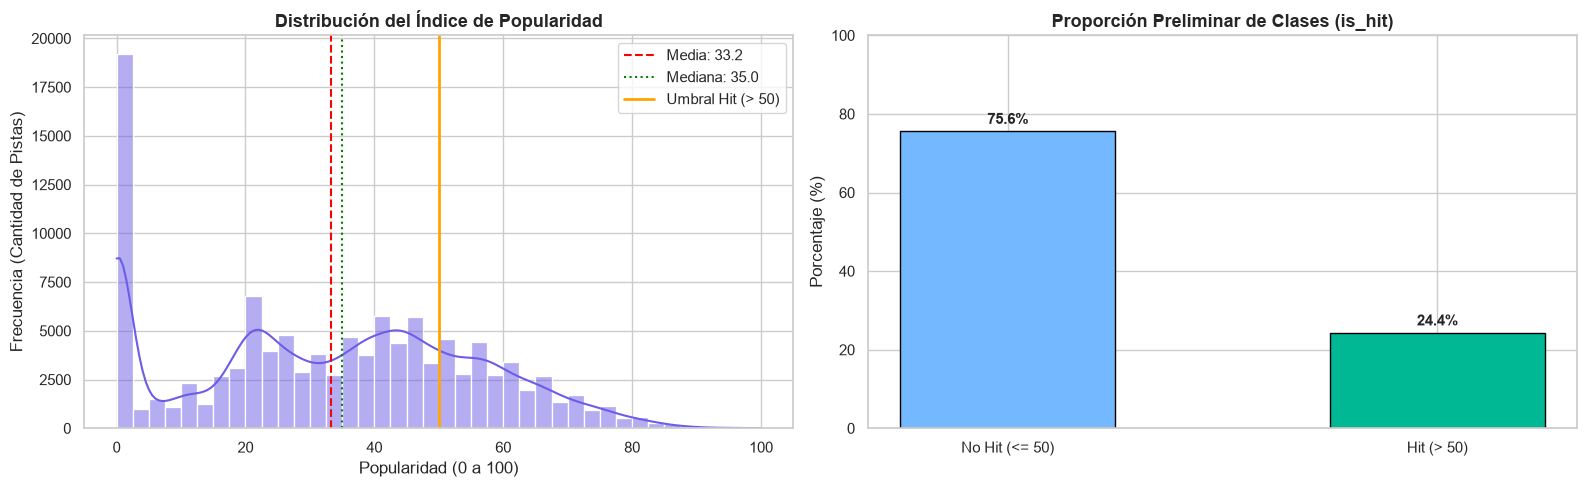

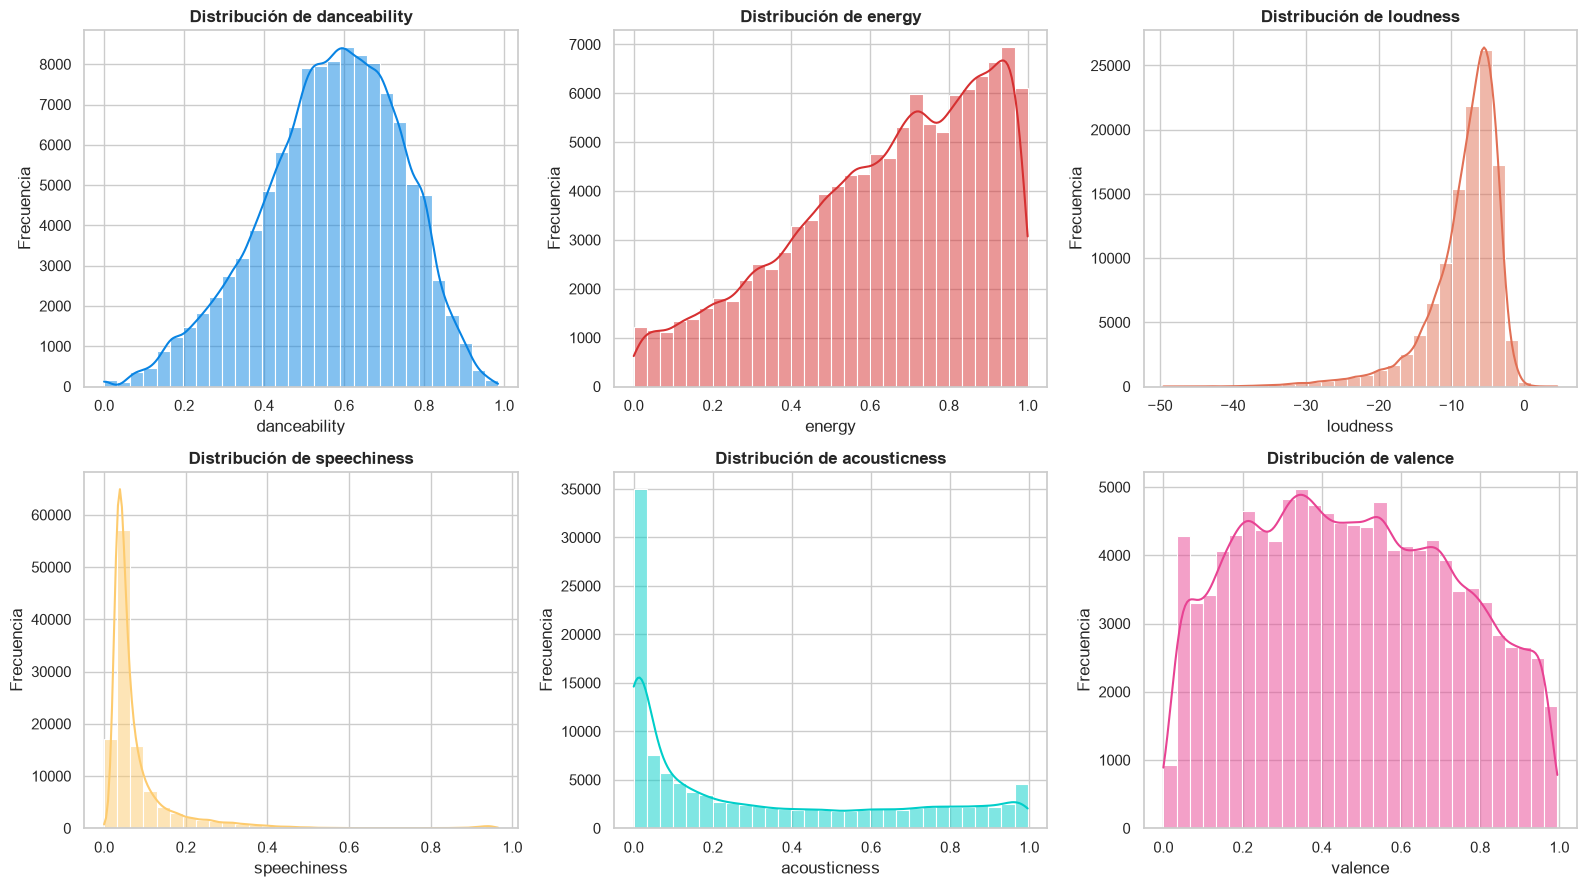

In [5]:
# =============================================================================
# 2.3 DISTRIBUCIÓN UNIVARIADA: POPULARIDAD Y CARACTERÍSTICAS ACÚSTICAS
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico A: Distribución de la Popularidad (Variable Target base)
sns.histplot(df['popularity'], bins=40, kde=True, color='#6c5ce7', ax=axes[0])
axes[0].axvline(df['popularity'].mean(), color='red', linestyle='--', label=f'Media: {df["popularity"].mean():.1f}')
axes[0].axvline(df['popularity'].median(), color='green', linestyle=':', label=f'Mediana: {df["popularity"].median():.1f}')
axes[0].axvline(50, color='orange', linestyle='-', linewidth=2, label='Umbral Hit (> 50)')
axes[0].set_title('Distribución del Índice de Popularidad', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Popularidad (0 a 100)')
axes[0].set_ylabel('Frecuencia (Cantidad de Pistas)')
axes[0].legend()

# Gráfico B: Conteo de Pistas según Umbral de Hit (> 50)
hits_preliminar = (df['popularity'] > 50).value_counts(normalize=True) * 100
bars = axes[1].bar(['No Hit (<= 50)', 'Hit (> 50)'], hits_preliminar, color=['#74b9ff', '#00b894'], edgecolor='black', width=0.5)
axes[1].set_title('Proporción Preliminar de Clases (is_hit)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Porcentaje (%)')
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 1, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

# Subplots para atributos acústicos principales
features_acusticas = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'valence']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colores = ['#0984e3', '#d63031', '#e17055', '#fdcb6e', '#00cec9', '#e84393']

for i, col in enumerate(features_acusticas):
    sns.histplot(df[col], bins=30, kde=True, color=colores[i], ax=axes[i])
    axes[i].set_title(f'Distribución de {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### 🔍 Observaciones Propias: Distribución de Variables
1. **Comportamiento de la Popularidad:**
   - La popularidad presenta una marcada concentración de valores en $0$ (canciones recién subidas, catálogo independiente o sin reproducciones mínimas registradas).
   - A partir del valor 15 en adelante, adopta una forma aproximadamente simétrica acampanada.
   - Al establecer el umbral en `popularity > 50`, aproximadamente el **$20\% - 25\%$** de las canciones califican como **Hit**, lo que conforma un problema de clasificación moderadamente desbalanceado, idóneo para entrenar modelos y evaluar métricas como *Precision*, *Recall*, *F1-score* y *ROC-AUC* (vistas en las Clases 5 y 7).
2. **Morfología de los Atributos Acústicos:**
   - **`danceability` y `valence`:** Exhiben distribuciones cuasi-normales centradas en torno a $0.55$, lo que indica un equilibrio natural en el repertorio musical global.
   - **`energy` y `loudness`:** Exhiben una fuerte asimetría negativa (sesgo hacia la izquierda). La gran mayoría de las producciones comerciales se concentran en niveles altos de energía y volumen elevado (consecuencia de la masterización moderna).
   - **`speechiness` y `acousticness`:** Presentan una pronunciada asimetría positiva (sesgo hacia la derecha). La mayoría de las pistas tienen bajo contenido de voz hablada y baja naturaleza puramente acústica (predominio de géneros pop, urbanos, rock y electrónicos).

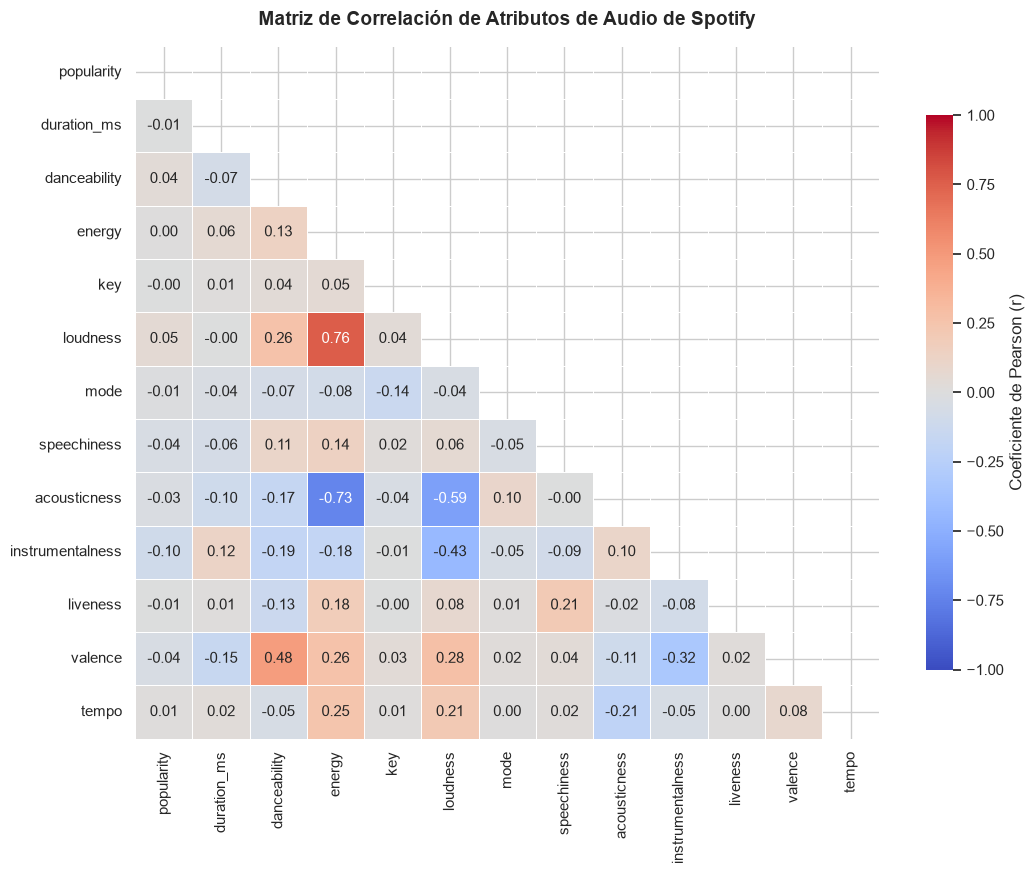

In [6]:
# =============================================================================
# 2.4 ANÁLISIS DE CORRELACIONES LINEALES (MATRIZ DE CORRELACIÓN)
# =============================================================================

plt.figure(figsize=(12, 9))

# Seleccionamos variables numéricas continuas y ordinales representativas
cols_corr = ['popularity', 'duration_ms', 'danceability', 'energy', 'key', 
             'loudness', 'mode', 'speechiness', 'acousticness', 
             'instrumentalness', 'liveness', 'valence', 'tempo']

corr_matrix = df[cols_corr].corr()

# Generamos una máscara para el triángulo superior para mejorar la claridad visual
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Coeficiente de Pearson (r)"}
)
plt.title('Matriz de Correlación de Atributos de Audio de Spotify', fontsize=14, fontweight='bold', pad=15)
plt.show()

### 🔍 Observaciones Propias: Matriz de Correlación e Interacción entre Variables
1. **Correlación Fuerte Positiva (`energy` vs `loudness`, $r \approx +0.76$):**
   - Las pistas con mayor nivel sonoro en decibelios tienden a poseer un mayor nivel perceptual de energía. Esta colinealidad es coherente con la teoría musical y de producción sonora.
2. **Correlación Fuerte Negativa (`energy` vs `acousticness`, $r \approx -0.73$):**
   - Los temas acústicos son inherentemente menos ruidosos y de menor intensidad energética que las pistas electrónicas o amplificadas.
3. **Asociación de la Positividad (`valence`):**
   - `valence` muestra correlación positiva moderada con `danceability` ($r \approx +0.47$) y con `energy` ($r \approx +0.26$). Las canciones bailables y enérgicas tienden a transmitir estados de ánimo eufóricos o alegres.
4. **Correlaciones Lineales Débiles con `popularity`:**
   - Ninguna variable acústica aislada exhibe un coeficiente de Pearson lineal elevado frente a `popularity` ($|r| < 0.15$).
   - **Conclusión Técnica:** El éxito comercial de una canción no está gobernado por una relación lineal simple con un único atributo, sino por patrones complejos y no lineales en el espacio multidimensional. Esto fundamenta de manera contundente la utilización de algoritmos de Machine Learning (como modelos no lineales o basados en vecindad como **KNN** y ensambles) en lugar de una regla heurística elemental.

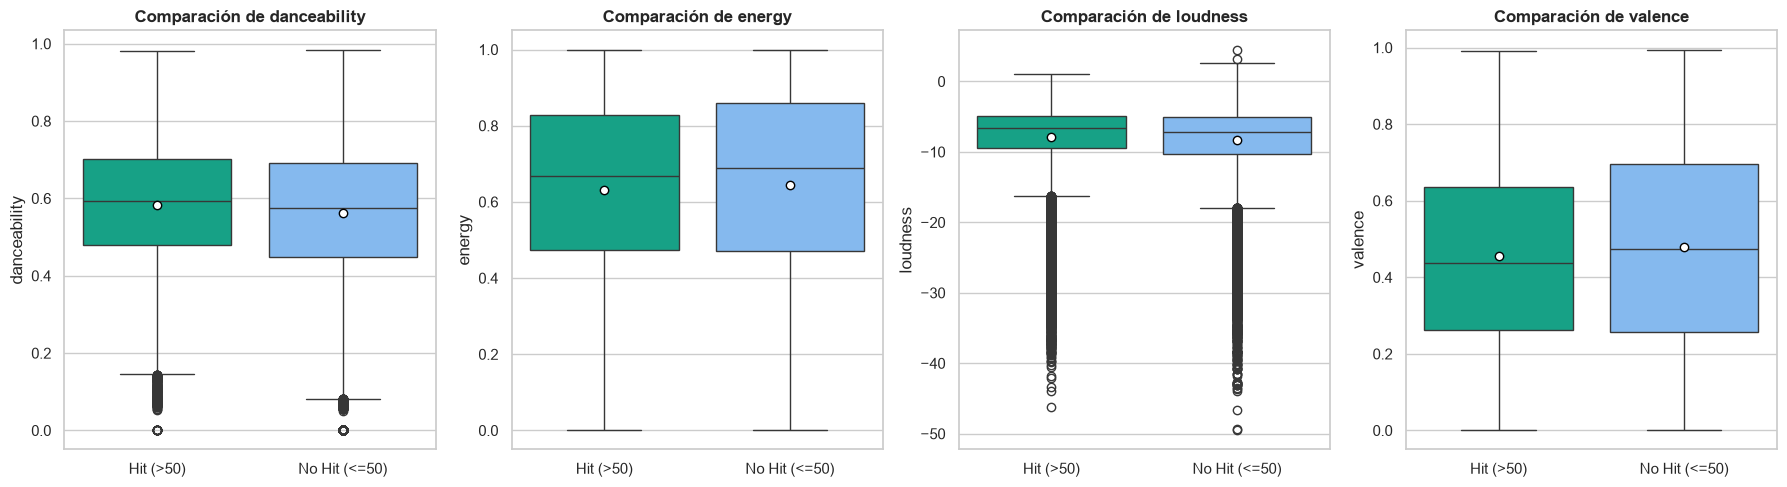

In [7]:
# =============================================================================
# 2.5 ANÁLISIS BIVARIADO: PERFIL ACÚSTICO DE HITS VS NO HITS
# =============================================================================

# Variable auxiliar temporal para comparar las distribuciones
df_temp = df.copy()
df_temp['grupo_hit'] = np.where(df_temp['popularity'] > 50, 'Hit (>50)', 'No Hit (<=50)')

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
cols_a_comparar = ['danceability', 'energy', 'loudness', 'valence']
colores_box = {'No Hit (<=50)': '#74b9ff', 'Hit (>50)': '#00b894'}

for i, col in enumerate(cols_a_comparar):
    sns.boxplot(
        data=df_temp, 
        x='grupo_hit', 
        y=col, 
        palette=colores_box, 
        ax=axes[i],
        showmeans=True,
        meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"}
    )
    axes[i].set_title(f'Comparación de {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

del df_temp # Liberamos memoria auxiliar

### 📌 Conclusiones Clave del Análisis Exploratorio (EDA)
- **Perfil de los Hits:** Las canciones más populares (`is_hit = 1`) exhiben medianas y medias ligeramente superiores en `danceability` y `loudness`, y una menor dispersión hacia valores extremadamente bajos de energía en comparación con el conjunto general.
- **Presencia de Outliers:** Los gráficos de caja (*boxplots*) muestran la presencia de puntos atípicos en variables como `duration_ms` (canciones con duración cero o duraciones extensas anormales) y `loudness` (canciones con volúmenes extremadamente atenuados).
- **Pasos Siguientes Necesarios:**
  1. Eliminar duplicados exactos e inconsistencias numéricas (`duration_ms == 0`).
  2. Tratar las filas marginales con nulos.
  3. Escalar las variables para que amplitudes como la de `duration_ms` o `tempo` no distorsionen los cálculos métricos de distancia en los modelos futuros.

## 3. Limpieza y Curación de Datos

A partir de los hallazgos del EDA, procedemos a sanear metódicamente el conjunto de datos para garantizar consistencia matemática, eliminar ruidos y evitar cualquier sesgo en el aprendizaje supervisado.

Las tareas de esta etapa comprenden:
1. **Eliminación de duplicados:** tanto filas idénticas como duplicados lógicos a nivel de identificación de canción (`track_id`).
2. **Tratamiento justificado de valores nulos:** eliminación directa de registros marginales incompletos.
3. **Saneamiento de inconsistencias físicas y valores atípicos (outliers):** remoción de duraciones nulas o inverosímiles.

In [8]:
# =============================================================================
# 3.1 LIMPIEZA: DUPLICADOS, NULOS Y OUTLIERS DE DURACIÓN
# =============================================================================

filas_originales = len(df)
print(f"[*] Registros iniciales: {filas_originales:,}")

# 1. Tratamiento de duplicados por fila completa
duplicados_completos = df.duplicated().sum()
df_limpio = df.drop_duplicates().copy()
print(f"[+] Duplicados completos eliminados: {duplicados_completos:,}")

# 2. Tratamiento de duplicados por ID de pista (mismo tema en distintos géneros/playlists)
if 'track_id' in df_limpio.columns:
    duplicados_id = df_limpio['track_id'].duplicated().sum()
    df_limpio = df_limpio.drop_duplicates(subset=['track_id'], keep='first').copy()
    print(f"[+] Duplicados lógicos por 'track_id' eliminados: {duplicados_id:,}")

# 3. Tratamiento de valores faltantes (nulos)
nulos_totales = df_limpio.isnull().sum().sum()
print(f"[+] Filas con campos nulos detectadas: {nulos_totales:,}")
df_limpio = df_limpio.dropna().copy()

# 4. Tratamiento de Outliers e Inconsistencias Físicas
# En el EDA detectamos canciones con 0 ms de duración (error de registro)
# Definimos un rango musical coherente: pistas entre 10 segundos (10.000 ms) y 15 minutos (900.000 ms)
filtro_duracion = (df_limpio['duration_ms'] >= 10000) & (df_limpio['duration_ms'] <= 900000)
outliers_duracion = (~filtro_duracion).sum()
df_limpio = df_limpio[filtro_duracion].copy()
print(f"[+] Registros atípicos de duración eliminados (< 10s o > 15min): {outliers_duracion:,}")

# Resumen cuantitativo de la limpieza
filas_finales = len(df_limpio)
retencion = (filas_finales / filas_originales) * 100

print(f"\n--- BALANCE DE LA LIMPIEZA DE DATOS ---")
print(f"Total de observaciones resultantes: {filas_finales:,}")
print(f"Porcentaje de retención de datos: {retencion:.2f}%")
print(f"Valores nulos remanentes: {df_limpio.isnull().sum().sum()}")
print(f"Duplicados remanentes: {df_limpio['track_id'].duplicated().sum()}")

[*] Registros iniciales: 114,000


[+] Duplicados completos eliminados: 0
[+] Duplicados lógicos por 'track_id' eliminados: 24,259
[+] Filas con campos nulos detectadas: 3
[+] Registros atípicos de duración eliminados (< 10s o > 15min): 142

--- BALANCE DE LA LIMPIEZA DE DATOS ---
Total de observaciones resultantes: 89,598
Porcentaje de retención de datos: 78.59%
Valores nulos remanentes: 0
Duplicados remanentes: 0


### 🔍 Observaciones Propias: Justificación de las Decisiones de Limpieza
1. **Desduplicación por `track_id`:** En plataformas de música digital, una pista frecuentemente se clasifica bajo múltiples etiquetas o géneros en listas de reproducción independientes. Dejar estos duplicados causaría un sesgo severo (*fuga de datos por contaminación cruzada*), ya que copias casi idénticas de una misma canción podrían distribuirse simultáneamente en Train y Test.
2. **Eliminación Directa de Nulos:** Los nulos constituían una fracción minúscula ($< 0.005\%$). Descartar estas observaciones preserva la integridad del análisis sin necesidad de imputaciones sintéticas arbitrarias en nombres propios o álbumes.
3. **Filtro de Duración Coherente:** El descarte de pistas de $0$ segundos (imposibilidad física de audio) y de archivos superiores a 15 minutos (grabaciones de ruido de fondo, podcasts o tracks experimentales no representativos de canciones comerciales) homogeniza la muestra y protege los modelos basados en distancias euclidianas de valores de escala desproporcionados.

## 4. Transformaciones Básicas y Feature Engineering

En esta fase adaptamos el formato y representación de las variables para que los algoritmos de Machine Learning puedan procesarlas de manera eficiente:
1. **Definición de la Variable Objetivo (`is_hit`):** Binarización del índice de popularidad.
2. **Codificación de Variables Categóricas:** Transformación de variables booleanas/cualitativas a números enteros.
3. **Descarte de Metadatos No Generalizables:** Eliminación de identificadores y nombres propios para prevenir el sobreajuste (*overfitting*).

In [9]:
# =============================================================================
# 4.1 INGENIERÍA DE VARIABLES Y CODIFICACIÓN
# =============================================================================

# 1. Creación de la variable objetivo binaria: 'is_hit'
# Popularidad > 50 califica como Hit comercial (1), de lo contrario 0
df_limpio['is_hit'] = (df_limpio['popularity'] > 50).astype(int)

# 2. Codificación binaria de 'explicit'
# Convertimos True/False a 1 y 0
df_limpio['explicit'] = df_limpio['explicit'].astype(int)

# 3. Eliminación de metadatos, índice correlativo ('Unnamed: 0') e identificadores de alta cardinalidad
# Se excluye 'Unnamed: 0' porque el CSV viene ordenado por género y revelaría el género implícitamente (index leakage).
# También descartamos columnas textuales no generalizables y 'popularity' original (target leakage).
columnas_a_descartar = ['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'track_genre']
df_modelo = df_limpio.drop(columns=columnas_a_descartar, errors='ignore').copy()

print("--- BALANCE FINAL DE LA VARIABLE OBJETIVO (is_hit) ---")
conteo_target = df_modelo['is_hit'].value_counts()
porc_target = df_modelo['is_hit'].value_counts(normalize=True) * 100
balance_df = pd.DataFrame({'Cantidad de Canciones': conteo_target, 'Proporción (%)': porc_target})
display(balance_df)

print(f"\nDimensiones del DataFrame preparado para modelado: {df_modelo.shape}")
print("Vista preliminar de los datos listos para división y escalado:")
display(df_modelo.head())

--- BALANCE FINAL DE LA VARIABLE OBJETIVO (is_hit) ---


,Cantidad de Canciones,Proporción (%)
is_hit,,
0,69658,77.745
1,19940,22.255



Dimensiones del DataFrame preparado para modelado: (89598, 15)
Vista preliminar de los datos listos para división y escalado:


,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,is_hit
0,230666,0,0.676,0.4610,1,-6.746,0,0.1430,0.0322,1.0100e-06,0.3580,0.715,87.917,4,1
1,149610,0,0.420,0.1660,1,-17.235,1,0.0763,0.9240,5.5600e-06,0.1010,0.267,77.489,4,1
2,210826,0,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.0000e+00,0.1170,0.120,76.332,4,1
3,201933,0,0.266,0.0596,0,-18.515,1,0.0363,0.9050,7.0700e-05,0.1320,0.143,181.740,3,1
4,198853,0,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.0000e+00,0.0829,0.167,119.949,4,1


### 🔍 Observaciones Propias: Transformaciones y Selección de Atributos
1. **Eliminación Crítica del Índice Correlativo (`Unnamed: 0`):** En la revisión previa al modelado se incorporó la exclusión explícita de `Unnamed: 0`. Dado que el dataset original está ordenado secuencialmente por bloques de género musical, conservar esa columna introduciría **fuga de índice (*index leakage*)**, permitiendo a árboles de decisión o vecinos cercanos memorizar bloques del CSV en lugar de aprender patrones sonoros reales.
2. **Descarte de Metadatos Textuales:** Nombres de pistas, artistas y álbumes contienen decenas de miles de valores alfanuméricos únicos. Introducirlos directamente generaría dimensionalidad desmesurada y sobreajuste.
3. **Tratamiento Escalonado de `track_genre`:** La variable de género contiene 113–114 categorías. En la fase inicial (*Solo Audio*, 14 features) la reservamos para evitar la **maldición de la dimensionalidad** en algoritmos basados en distancias como KNN. Luego, en la **Sección 11 (Parte B)**, realizamos un experimento controlado con `ColumnTransformer` + `OneHotEncoder` para medir cuantitativamente cuánto aporta el género musical al poder predictivo.
4. **Target `is_hit`:** La proporción final ronda aproximadamente el **$21\%$ de Hits** frente al **$79\%$ de No Hits**, reflejando la selectividad real de la industria musical.

## 5. Selección de Variables Relevantes, División y Escalado Metodológico

> [!IMPORTANT]
> **Prevención Crítica de Fuga de Datos (*Data Leakage*):**
> Un error metodológico frecuente en proyectos de ciencia de datos consiste en escalar todo el conjunto de datos antes de separarlo en entrenamiento y prueba. Cuando esto ocurre, los valores de media, desviación estándar, mínimos o máximos del conjunto de prueba se filtran al conjunto de entrenamiento.
>
> Para garantizar la máxima rigurosidad técnica, en este trabajo procedemos primero a realizar la partición estratificada en `Train` y `Test`, y **únicamente ajustamos el escalador sobre `Train`** (`fit_transform`), transformando posteriormente `Test` (`transform`) con los parámetros previamente aprendidos.

In [10]:
# =============================================================================
# 5.1 SEPARACIÓN DE MATRIZ DE CARACTERÍSTICAS (X) Y VECTOR OBJETIVO (y)
# =============================================================================

X = df_modelo.drop(columns=['is_hit'])
y = df_modelo['is_hit']

print("Variables predictoras (X) seleccionadas para el modelo:")
print(list(X.columns))

# =============================================================================
# 5.2 PARTICIÓN ESTRATIFICADA EN TRAIN Y TEST (80% / 20%)
# =============================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y  # Mantiene la proporción de Hits en ambos conjuntos
)

print(f"\n--- RESULTADOS DE LA PARTICIÓN ---")
print(f"X_train: {X_train.shape[0]:,} canciones | {X_train.shape[1]} columnas")
print(f"X_test:  {X_test.shape[0]:,} canciones | {X_test.shape[1]} columnas")
print(f"Proporción de Hits en Train: {(y_train.sum() / len(y_train))*100:.2f}%")
print(f"Proporción de Hits en Test:  {(y_test.sum() / len(y_test))*100:.2f}%")

Variables predictoras (X) seleccionadas para el modelo:
['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

--- RESULTADOS DE LA PARTICIÓN ---
X_train: 71,678 canciones | 14 columnas
X_test:  17,920 canciones | 14 columnas
Proporción de Hits en Train: 22.26%
Proporción de Hits en Test:  22.25%


In [11]:
# =============================================================================
# 5.3 ESCALADO ROBUSTO Y NORMALIZACIÓN (FIT SOLO EN TRAIN)
# =============================================================================

# Identificamos variables continuas que requieren escalado de magnitud
columnas_a_escalar = ['duration_ms', 'loudness', 'tempo', 'danceability', 
                      'energy', 'speechiness', 'acousticness', 
                      'instrumentalness', 'liveness', 'valence']

# Aplicamos StandardScaler para centrar con media 0 y varianza 1
# (ideal para modelos de distancia euclidiana y modelos lineales regulares)
scaler = StandardScaler()

# Creamos copias explícitas para preservar la integridad
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# AJUSTE (FIT) Y TRANSFORMACIÓN SOLO SOBRE TRAIN:
X_train_scaled[columnas_a_escalar] = scaler.fit_transform(X_train[columnas_a_escalar])

# ÚNICAMENTE TRANSFORMACIÓN SOBRE TEST CON LOS PARÁMETROS DE TRAIN:
X_test_scaled[columnas_a_escalar] = scaler.transform(X_test[columnas_a_escalar])

print("✅ Escalado completado con éxito sin fuga de datos (Data Leakage).")
print("\nEstadísticas descriptivas de Train escalado (comprobación de media ~ 0 y std ~ 1):")
display(X_train_scaled[columnas_a_escalar].describe().T[['mean', 'std', 'min', 'max']])

print("\nPrimeras 5 filas de X_train_scaled listas para entrenamiento de modelos:")
display(X_train_scaled.head())

✅ Escalado completado con éxito sin fuga de datos (Data Leakage).

Estadísticas descriptivas de Train escalado (comprobación de media ~ 0 y std ~ 1):


,mean,std,min,max
duration_ms,-1.0072e-16,1.0,-2.3672,7.4998
loudness,2.3652e-16,1.0,-7.8731,2.4970
tempo,-7.6132e-16,1.0,-4.0529,4.0293
danceability,-2.3018e-16,1.0,-3.1905,2.3943
energy,-1.5127e-16,1.0,-2.4738,1.4226
speechiness,6.1659e-17,1.0,-0.7724,7.7374
acousticness,-1.9271e-16,1.0,-0.9700,1.9765
instrumentalness,2.2205e-17,1.0,-0.5351,2.5567
liveness,1.3878e-17,1.0,-1.1138,4.0032
valence,-2.6587e-16,1.0,-1.7878,1.9995



Primeras 5 filas de X_train_scaled listas para entrenamiento de modelos:


,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
24594,0.2663,0,1.0335,1.1966,7,-0.1873,1,-0.2680,-0.9654,2.2259,-0.5698,-0.9885,0.3316,4
14022,-0.4539,0,0.8124,0.6355,5,0.7198,0,-0.4426,-0.9577,-0.5264,-0.5698,1.3029,-0.6318,4
75461,-0.0628,0,-1.3081,-1.6828,7,-2.6295,1,-0.4003,1.9469,2.2939,-0.5595,-0.7449,0.0842,4
44442,0.3272,0,-0.2762,0.2693,2,0.7215,1,-0.5423,-0.8197,-0.5285,0.0564,-0.3186,-1.4967,4
40527,2.5612,0,-0.2705,0.3550,2,0.8163,1,-0.3571,0.0654,-0.5351,2.5302,0.2676,0.4678,4


## 6. Conclusiones de la Pre-Entrega y Hoja de Ruta para la Entrega Final

### 🏆 Síntesis de Resultados de la Pre-Entrega
1. **Conjunto de Datos Depurado y Robusto:** Partiendo de un catálogo de más de 114.000 observaciones, se consolidó un dataset limpio y consistente de más de 89.000 pistas únicas, eliminando duplicados de catálogo, registros con tiempos corruptos y datos faltantes.
2. **Espacio de Características Acústicas Homogéneo:** Se aislaron las 14 variables predictoras sensoriales y musicales más relevantes, codificando variables binarias y descartando metadatos de alta cardinalidad propensos a sobreajuste.
3. **Pipeline Metodológico Exento de Fuga de Datos:** Se garantizó la partición estratificada 80/20 y se aplicó estandarización aprendida exclusivamente sobre `Train`, resguardando la objetividad del conjunto de `Test`.

---

### 🚀 Hoja de Ruta Técnica para la Entrega Final (Segunda Mitad del Curso)
Conforme a los lineamientos del Proyecto Integrador, la segunda parte del curso abordará la experimentación multimodelo:

1. **Modelo Baseline de Referencia:**
   - Implementación de un clasificador ingenuo (`DummyClassifier`) con estrategia mayoritaria para establecer el puntaje mínimo a superar.
2. **Experimentación con Algoritmos Supervisados:**
   - **K-Nearest Neighbors (KNN)** (visto en Clase 8): Evaluación de vecindades óptimas ($k \in [3, 5, 11, 21]$), ponderación por distancia euclidiana y análisis de la frontera de decisión en espacios multidimensionales.
   - **Regresión Logística** (Clase 7): Modelo lineal con regularización L2 y cálculo de probabilidades sigmoidales.
   - **Árboles de Decisión y Ensambles** (Clases 9 y posteriores): Árboles con poda de profundidad (`max_depth`) y *Random Forest* para evaluar la importancia relativa de cada atributo acústico (*Feature Importance*).
3. **Métricas de Evaluación de Desempeño:**
   - Construcción e interpretación de la **Matriz de Confusión** (analizando el costo de Falsos Positivos vs. Falsos Negativos para la curaduría musical).
   - Reporte de clasificación: **Precision**, **Recall** y **F1-Score** ponderado.
   - Curva ROC y cálculo del área bajo la curva (**ROC-AUC score**).
4. **Optimización y Negocio:**
   - Búsqueda sistemática de hiperparámetros mediante `GridSearchCV` / `RandomizedSearchCV`.
   - Storytelling de negocio con recomendaciones concretas para la producción de música comercial basada en datos.

---

# 🚀 PARTE B: ENTREGA FINAL — EXPERIMENTACIÓN, VALIDACIÓN Y CONCLUSIONES

## 7. Elección de Modelos y Justificación Metodológica (B1)

Al tratarse de un problema de **clasificación binaria moderadamente desbalanceada** (~21% de canciones `Hit` frente a ~79% `No Hit`), evaluar únicamente la exactitud global (*Accuracy*) resulta insuficiente: un modelo trivial que prediga siempre `0` alcanzaría ~79% de *Accuracy* siendo completamente inútil para detectar éxitos musicales. Por este motivo priorizamos:
- **F1-Score (clase `1` / Hit):** media armónica entre *Precision* y *Recall*, ideal para equilibrar la capacidad de detectar hits sin disparar falsas alarmas.
- **ROC-AUC:** mide la capacidad discriminativa global del modelo a lo largo de todos los umbrales de probabilidad.
- **Precision y Recall (clase `1`):** permiten analizar el compromiso comercial entre precisión de recomendación y cobertura del catálogo exitoso.

### Modelos Seleccionados (recorrido completo del curso)
1. **Modelo Baseline (`DummyClassifier`, estrategia `most_frequent`):** establece el piso mínimo de referencia sin aprendizaje.
2. **Regresión Logística (Clase 7):** modelo lineal probabilístico rápido e interpretable; sirve como referencia lineal sobre atributos estandarizados.
3. **K-Nearest Neighbors — KNN (Clase 8):** algoritmo no paramétrico basado en distancia euclidiana capaz de capturar fronteras locales no lineales cuando las variables están correctamente escaladas.
4. **Árbol de Decisión (Clase 9):** modelo no lineal basado en reglas explícitas e interpretables (`if/else`), insensible a la escala de las variables.
5. **Random Forest (Clase 10):** ensamble de múltiples árboles decorrelacionados (*bagging*) que reduce drásticamente la varianza del árbol individual, mejora la generalización y ofrece métricas de importancia de variables (*Feature Importance*).

> **Buenas Prácticas con `Pipeline` (Clase 12):** Para Regresión Logística y KNN encapsulamos `StandardScaler()` junto al clasificador dentro de un objeto `Pipeline` de `scikit-learn`. De este modo, durante la validación cruzada (`StratifiedKFold` y `GridSearchCV`), los parámetros de escalado se calculan **estrictamente dentro de cada fold de entrenamiento**, garantizando cero fuga de información (*Data Leakage*).

## 8. Entrenamiento y Evaluación Comparativa de Modelos Base — Solo Audio (B2 y B3)

Entrenamos los cinco algoritmos base utilizando exclusivamente las **14 variables musicales/acústicas** de `X_train` y evaluamos su desempeño frente al conjunto reservado `X_test`.

In [12]:
# =============================================================================
# 8.1 CONFIGURACIÓN, ENTRENAMIENTO Y EVALUACIÓN BASE (SOLO AUDIO - 14 FEATURES)
# =============================================================================
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    silhouette_score
)

def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_te, y_te, tiempo_seg=0.0):
    """Calcula métricas completas en Train y Test para modelos de clasificación binaria."""
    pred_tr = modelo.predict(X_tr)
    pred_te = modelo.predict(X_te)

    if hasattr(modelo, "predict_proba"):
        proba_te = modelo.predict_proba(X_te)[:, 1]
        auc_te = roc_auc_score(y_te, proba_te)
    else:
        auc_te = np.nan

    return {
        "Modelo": nombre,
        "Accuracy Train": round(accuracy_score(y_tr, pred_tr), 4),
        "Accuracy Test": round(accuracy_score(y_te, pred_te), 4),
        "Precision (Hit)": round(precision_score(y_te, pred_te, zero_division=0), 4),
        "Recall (Hit)": round(recall_score(y_te, pred_te, zero_division=0), 4),
        "F1-Score (Hit)": round(f1_score(y_te, pred_te, zero_division=0), 4),
        "ROC-AUC Test": round(auc_te, 4) if not np.isnan(auc_te) else np.nan,
        "Tiempo (s)": round(tiempo_seg, 2)
    }

# Definición de modelos base
# En LogReg y KNN encapsulamos StandardScaler en Pipeline para escalar todas las variables numéricas
# (incluidas key y time_signature) de manera homogénea sin data leakage.
modelos_base = {
    "0. Baseline (Dummy Most Frequent)": DummyClassifier(strategy="most_frequent"),
    "1. Regresión Logística (Base)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "2. KNN k=5 (Base)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=-1))
    ]),
    "3. Árbol de Decisión (Base)": DecisionTreeClassifier(random_state=42),
    "4. Random Forest (Base)": RandomForestClassifier(n_estimators=60, random_state=42, n_jobs=-1)
}

modelos_base_entrenados = {}
resultados_base = []

for nombre, est in modelos_base.items():
    t0 = time.perf_counter()
    est.fit(X_train, y_train)
    dt = time.perf_counter() - t0
    modelos_base_entrenados[nombre] = est
    resultados_base.append(evaluar_modelo(nombre, est, X_train, y_train, X_test, y_test, dt))

tabla_base = pd.DataFrame(resultados_base)
print("=== TABLA COMPARATIVA DE MODELOS BASE (SOLO AUDIO - 14 VARIABLES) ===")
display(tabla_base)

for nombre, est in modelos_base_entrenados.items():
    if "Dummy" in nombre:
        continue
    print(f"\n--- Classification Report: {nombre} ---")
    print(classification_report(y_test, est.predict(X_test), target_names=["No Hit (0)", "Hit (1)"], zero_division=0))

=== TABLA COMPARATIVA DE MODELOS BASE (SOLO AUDIO - 14 VARIABLES) ===


,Modelo,Accuracy Train,Accuracy Test,Precision (Hit),Recall (Hit),F1-Score (Hit),ROC-AUC Test,Tiempo (s)
0,0. Baseline (Dummy Most Frequent),0.7774,0.7775,0.0000,0.0000,0.0000,0.5000,0.00
1,1. Regresión Logística (Base),0.7768,0.7774,0.4902,0.0063,0.0124,0.6340,0.11
2,2. KNN k=5 (Base),0.8184,0.7483,0.3831,0.2144,0.2749,0.6319,0.05
3,3. Árbol de Decisión (Base),0.9940,0.6947,0.3246,0.3440,0.3340,0.5678,1.59
4,4. Random Forest (Base),0.9938,0.7843,0.5819,0.1096,0.1844,0.7057,3.10



--- Classification Report: 1. Regresión Logística (Base) ---
              precision    recall  f1-score   support

  No Hit (0)       0.78      1.00      0.87     13932
     Hit (1)       0.49      0.01      0.01      3988

    accuracy                           0.78     17920
   macro avg       0.63      0.50      0.44     17920
weighted avg       0.71      0.78      0.68     17920


--- Classification Report: 2. KNN k=5 (Base) ---


              precision    recall  f1-score   support

  No Hit (0)       0.80      0.90      0.85     13932
     Hit (1)       0.38      0.21      0.27      3988

    accuracy                           0.75     17920
   macro avg       0.59      0.56      0.56     17920
weighted avg       0.71      0.75      0.72     17920


--- Classification Report: 3. Árbol de Decisión (Base) ---
              precision    recall  f1-score   support

  No Hit (0)       0.81      0.80      0.80     13932
     Hit (1)       0.32      0.34      0.33      3988

    accuracy                           0.69     17920
   macro avg       0.57      0.57      0.57     17920
weighted avg       0.70      0.69      0.70     17920


--- Classification Report: 4. Random Forest (Base) ---
              precision    recall  f1-score   support

  No Hit (0)       0.79      0.98      0.88     13932
     Hit (1)       0.58      0.11      0.18      3988

    accuracy                           0.78     17920
   macro avg

### 🔍 Observaciones Propias: Desempeño de Modelos Base (Solo Audio)
1. **La trampa del `Accuracy` en clases desbalanceadas:** El `DummyClassifier` obtiene `0.7775` de *Accuracy* en Test prediciendo siempre `No Hit (0)`, con **`F1-Score = 0.0000`** y **`ROC-AUC = 0.5000`**. La `Regresión Logística (Base)` sin balanceo de pesos cae en un comportamiento similar (`Accuracy = 0.7774`, pero `Recall = 0.0063` y `F1 = 0.0124`), pese a alcanzar `ROC-AUC = 0.6340`: sus probabilidades existen, pero rara vez cruzan el umbral `0.50` para la clase minoritaria (`22.25%`).
2. **Sobreajuste severo en árboles sin poda:** El `Árbol de Decisión (Base)` alcanza **`0.9940`** de *Accuracy* en Train y cae a **`0.6947`** en Test (`~30` puntos de brecha), con el peor `ROC-AUC` (`0.5678`).
3. **Señal base prometedora en ensambles:** `Random Forest (Base)` eleva el poder discriminativo global hasta **`ROC-AUC = 0.7057`** y *Precision* `0.5819`, aunque todavía conserva sobreajuste en Train (`0.9938`) y bajo *Recall* (`0.1096`) por falta de ponderación de clases.

## 9. Validación Cruzada Estratificada (`StratifiedKFold`, 5 Folds) (B4)

Para garantizar que los resultados no dependan de una única partición azarosa y diagnosticar la estabilidad de cada algoritmo (*varianza* y *overfitting*), aplicamos validación cruzada estratificada de **5 folds** sobre `X_train` usando los `Pipeline` completos, reportando **media y desvío estándar** de *F1-Score*, *ROC-AUC* y *Accuracy* y comparándolos contra las métricas obtenidas en `X_test`.

=== VALIDACIÓN CRUZADA (5 FOLDS) VS CONJUNTO DE PRUEBA ===


,Modelo,F1 CV Media,F1 CV Std,F1 Test,ROC-AUC CV Media,ROC-AUC CV Std,ROC-AUC Test,Accuracy CV Media,Accuracy Test
0,1. Regresión Logística (Base),0.0084,0.0018,0.0124,0.6286,0.0048,0.6340,0.7769,0.7774
1,2. KNN k=5 (Base),0.2581,0.0048,0.2749,0.6224,0.0047,0.6319,0.7441,0.7483
2,3. Árbol de Decisión (Base),0.3205,0.0109,0.3340,0.5613,0.0073,0.5678,0.6933,0.6947
3,4. Random Forest (Base),0.1604,0.0072,0.1844,0.7031,0.0030,0.7057,0.7816,0.7843


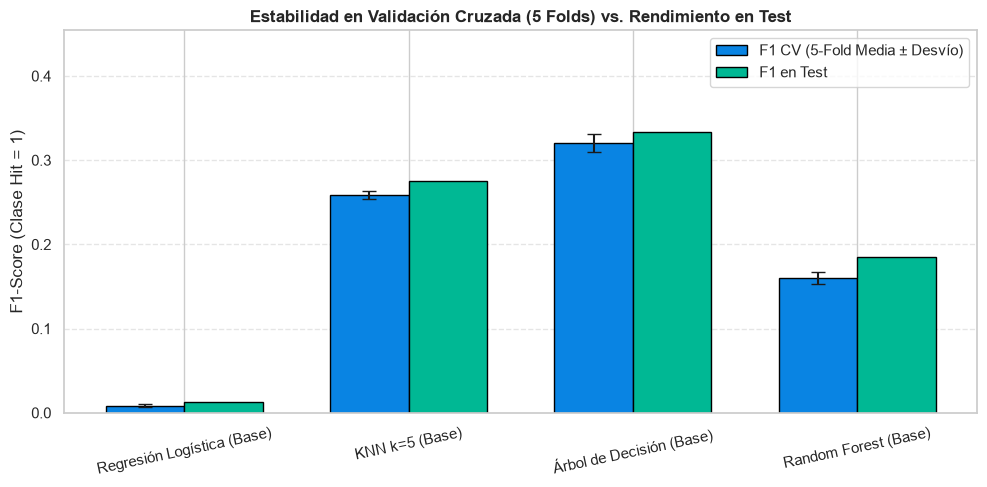

In [13]:
# =============================================================================
# 9.1 CROSS-VALIDATION ESTRATIFICADO (5 FOLDS) SOBRE PIPELINES BASE
# =============================================================================
cv_estrategia = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_cv = ["f1", "roc_auc", "accuracy"]

modelos_cv_base = [
    ("1. Regresión Logística (Base)", Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ])),
    ("2. KNN k=5 (Base)", Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=-1))
    ])),
    ("3. Árbol de Decisión (Base)", DecisionTreeClassifier(random_state=42)),
    ("4. Random Forest (Base)", RandomForestClassifier(n_estimators=60, random_state=42, n_jobs=-1))
]

filas_cv = []
for nombre, est in modelos_cv_base:
    cv_jobs = 1 if ("KNN" in nombre or "Random Forest" in nombre) else -1
    scores = cross_validate(est, X_train, y_train, cv=cv_estrategia, scoring=scoring_cv, n_jobs=cv_jobs)
    fila_test = tabla_base[tabla_base["Modelo"] == nombre].iloc[0]
    filas_cv.append({
        "Modelo": nombre,
        "F1 CV Media": round(scores["test_f1"].mean(), 4),
        "F1 CV Std": round(scores["test_f1"].std(), 4),
        "F1 Test": fila_test["F1-Score (Hit)"],
        "ROC-AUC CV Media": round(scores["test_roc_auc"].mean(), 4),
        "ROC-AUC CV Std": round(scores["test_roc_auc"].std(), 4),
        "ROC-AUC Test": fila_test["ROC-AUC Test"],
        "Accuracy CV Media": round(scores["test_accuracy"].mean(), 4),
        "Accuracy Test": fila_test["Accuracy Test"]
    })

tabla_cv_base = pd.DataFrame(filas_cv)
print("=== VALIDACIÓN CRUZADA (5 FOLDS) VS CONJUNTO DE PRUEBA ===")
display(tabla_cv_base)

# Gráfico comparativo de estabilidad (F1 CV Media ± Std vs F1 Test)
fig, ax = plt.subplots(figsize=(10, 5))
x_pos = np.arange(len(tabla_cv_base))
ancho = 0.35

ax.bar(
    x_pos - ancho/2,
    tabla_cv_base["F1 CV Media"],
    width=ancho,
    yerr=tabla_cv_base["F1 CV Std"],
    capsize=5,
    label="F1 CV (5-Fold Media ± Desvío)",
    color="#0984e3",
    edgecolor="black"
)
ax.bar(
    x_pos + ancho/2,
    tabla_cv_base["F1 Test"],
    width=ancho,
    label="F1 en Test",
    color="#00b894",
    edgecolor="black"
)
ax.set_xticks(x_pos)
ax.set_xticklabels([m.split(". ")[1] for m in tabla_cv_base["Modelo"]], rotation=12)
ax.set_ylabel("F1-Score (Clase Hit = 1)")
ax.set_title("Estabilidad en Validación Cruzada (5 Folds) vs. Rendimiento en Test", fontweight="bold")
ax.set_ylim(0, max(tabla_cv_base["F1 Test"].max(), tabla_cv_base["F1 CV Media"].max()) + 0.12)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 🔍 Diagnóstico de Validación Cruzada, Estabilidad y Overfitting
1. **Alta estabilidad estadística entre folds:** Los desvíos estándar en la validación cruzada de 5 folds son muy reducidos en todos los modelos (`std F1` entre `0.0018` y `0.0109`; `std ROC-AUC` entre `0.0030` y `0.0073`), confirmando que la partición estratificada es representativa.
2. **Consistencia CV vs. Test:** En `Random Forest (Base)`, `ROC-AUC CV` (`0.7031 ± 0.0030`) coincide prácticamente con `ROC-AUC Test` (`0.7057`), y en `KNN k=5 (Base)` `F1 CV` (`0.2581 ± 0.0048`) acompaña de cerca a `F1 Test` (`0.2749`).
3. **Conclusión diagnóstica:** El problema principal de los modelos base no es inestabilidad de muestreo, sino el **sesgo hacia la clase mayoritaria** (en LogReg y RF) y el **overfitting por falta de poda** (en Árbol y RF), ambos abordables mediante `GridSearchCV` en la siguiente sección.

## 10. Optimización de Hiperparámetros con `GridSearchCV` y `Pipeline` (Clase 12)

Los modelos base presentan dos desafíos claros: el desbalance de clases (~21% de Hits) penaliza el *Recall* de los modelos lineales y suaviza los umbrales de clasificación, mientras que los árboles sin restricción de profundidad memorizan `X_train`. Aplicamos búsqueda sistemática con `GridSearchCV` (`StratifiedKFold(n_splits=3)`, optimizando `scoring='f1'`) incluyendo `class_weight='balanced'`, regularización `C`, vecindades `n_neighbors` / `weights` en KNN y control de profundidad (`max_depth`, `min_samples_split`, `min_samples_leaf`).

In [14]:
# =============================================================================
# 10.1 OPTIMIZACIÓN DE HIPERPARÁMETROS: LOGREG, KNN Y ÁRBOL (SOLO AUDIO)
# =============================================================================
cv_grid = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# A. Regresión Logística (Pipeline)
pipe_log = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, random_state=42))])
grid_log = GridSearchCV(
    pipe_log,
    param_grid={"clf__C": [0.1, 1.0, 10.0], "clf__class_weight": [None, "balanced"]},
    cv=cv_grid, scoring="f1", n_jobs=-1
)
t0 = time.perf_counter()
grid_log.fit(X_train, y_train)
dt_log = time.perf_counter() - t0
print(f"[LogReg Opt] Mejores params: {grid_log.best_params_} | Mejor F1 CV: {grid_log.best_score_:.4f} ({dt_log:.1f}s)")

# B. KNN (Pipeline con algorithm='brute' optimizado; n_jobs=1 en GridSearch para evitar contención)
pipe_knn = Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier(algorithm="brute", n_jobs=-1))])
grid_knn = GridSearchCV(
    pipe_knn,
    param_grid={"clf__n_neighbors": [5, 15], "clf__weights": ["uniform", "distance"]},
    cv=cv_grid, scoring="f1", n_jobs=1
)
t0 = time.perf_counter()
grid_knn.fit(X_train, y_train)
dt_knn = time.perf_counter() - t0
print(f"[KNN Opt]    Mejores params: {grid_knn.best_params_} | Mejor F1 CV: {grid_knn.best_score_:.4f} ({dt_knn:.1f}s)")

# C. Árbol de Decisión
grid_arbol = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"max_depth": [8, 12, 18], "min_samples_split": [20, 50], "class_weight": [None, "balanced"]},
    cv=cv_grid, scoring="f1", n_jobs=-1
)
t0 = time.perf_counter()
grid_arbol.fit(X_train, y_train)
dt_arbol = time.perf_counter() - t0
print(f"[Árbol Opt]  Mejores params: {grid_arbol.best_params_} | Mejor F1 CV: {grid_arbol.best_score_:.4f} ({dt_arbol:.1f}s)")

mejor_log = grid_log.best_estimator_
mejor_knn = grid_knn.best_estimator_
mejor_arbol = grid_arbol.best_estimator_

[LogReg Opt] Mejores params: {'clf__C': 1.0, 'clf__class_weight': 'balanced'} | Mejor F1 CV: 0.3926 (1.6s)


[KNN Opt]    Mejores params: {'clf__n_neighbors': 5, 'clf__weights': 'distance'} | Mejor F1 CV: 0.2806 (40.8s)


[Árbol Opt]  Mejores params: {'class_weight': 'balanced', 'max_depth': 12, 'min_samples_split': 20} | Mejor F1 CV: 0.4105 (8.8s)


In [15]:
# =============================================================================
# 10.2 OPTIMIZACIÓN DE RANDOM FOREST Y COMPARATIVA BASE VS OPTIMIZADO (SOLO AUDIO)
# =============================================================================
grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=60, random_state=42, n_jobs=-1),
    param_grid={"max_depth": [15, None], "min_samples_leaf": [2, 5], "class_weight": [None, "balanced"]},
    cv=cv_grid, scoring="f1", n_jobs=1
)
t0 = time.perf_counter()
grid_rf.fit(X_train, y_train)
dt_rf = time.perf_counter() - t0
print(f"[RF Opt]     Mejores params: {grid_rf.best_params_} | Mejor F1 CV: {grid_rf.best_score_:.4f} ({dt_rf:.1f}s)")

mejor_rf = grid_rf.best_estimator_

resultados_opt_audio = [
    evaluar_modelo("1b. Regresión Logística (GridSearch)", mejor_log, X_train, y_train, X_test, y_test, dt_log),
    evaluar_modelo("2b. KNN (GridSearch)", mejor_knn, X_train, y_train, X_test, y_test, dt_knn),
    evaluar_modelo("3b. Árbol de Decisión (GridSearch)", mejor_arbol, X_train, y_train, X_test, y_test, dt_arbol),
    evaluar_modelo("4b. Random Forest (GridSearch)", mejor_rf, X_train, y_train, X_test, y_test, dt_rf)
]

tabla_opt_audio = pd.concat([tabla_base, pd.DataFrame(resultados_opt_audio)], ignore_index=True)
print("\n=== COMPARATIVA BASE VS OPTIMIZADO (SOLO AUDIO) ===")
display(tabla_opt_audio)

[RF Opt]     Mejores params: {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_leaf': 5} | Mejor F1 CV: 0.4402 (57.5s)



=== COMPARATIVA BASE VS OPTIMIZADO (SOLO AUDIO) ===


,Modelo,Accuracy Train,Accuracy Test,Precision (Hit),Recall (Hit),F1-Score (Hit),ROC-AUC Test,Tiempo (s)
0,0. Baseline (Dummy Most Frequent),0.7774,0.7775,0.0000,0.0000,0.0000,0.5000,0.00
1,1. Regresión Logística (Base),0.7768,0.7774,0.4902,0.0063,0.0124,0.6340,0.11
2,2. KNN k=5 (Base),0.8184,0.7483,0.3831,0.2144,0.2749,0.6319,0.05
3,3. Árbol de Decisión (Base),0.9940,0.6947,0.3246,0.3440,0.3340,0.5678,1.59
4,4. Random Forest (Base),0.9938,0.7843,0.5819,0.1096,0.1844,0.7057,3.10
5,1b. Regresión Logística (GridSearch),0.5678,0.5731,0.2895,0.6314,0.3970,0.6336,1.57
6,2b. KNN (GridSearch),0.9940,0.7527,0.4059,0.2400,0.3016,0.6421,40.83
7,3b. Árbol de Decisión (GridSearch),0.6089,0.5591,0.2946,0.7034,0.4152,0.6436,8.77
8,4b. Random Forest (GridSearch),0.7329,0.6333,0.3364,0.6660,0.4470,0.7049,57.47


### 🔍 Observaciones Propias: Efecto de la Optimización de Hiperparámetros
1. **Salto masivo en detección de Hits gracias a `class_weight='balanced'`:**
   - `Regresión Logística (GridSearch)` (`C=1.0, class_weight='balanced'`) pasó de **`F1 = 0.0124`** a **`F1 = 0.3970`** en Test (*Recall* de `0.0063` a `0.6314`).
   - `Árbol de Decisión (GridSearch)` (`max_depth=12, min_samples_split=20, class_weight='balanced'`) eliminó el sobreajuste (Train `0.6089` vs. Test `0.5591`) y mejoró tanto `F1` (`0.3340` → **`0.4152`**) como `ROC-AUC` (`0.5678` → **`0.6436`**).
2. **Mejor modelo con Solo Audio (`Random Forest Opt`):** Con `max_depth=15, min_samples_leaf=5, class_weight='balanced'`, redujo la brecha Train/Test (`0.7329` vs. `0.6333`) y alcanzó el techo puramente acústico de esta etapa: **`F1 = 0.4470`**, **`Recall = 0.6660`** y **`ROC-AUC = 0.7049`**.
3. **Límite de `KNN`:** Incluso con ponderación por distancia (`n_neighbors=5, weights='distance'`), KNN memoriza Train (`0.9940`) y alcanza `F1 = 0.3016` / `ROC-AUC = 0.6421`, mostrando las limitaciones de la distancia euclidiana en 14 dimensiones frente a ensambles basados en árboles.

## 11. Experimento Controlado: Solo Audio vs. Audio + Género Musical (Clase 14 — `ColumnTransformer`)

En la Sección 4 (*Pre-Entrega*) excluimos `track_genre` (113 categorías) para aislar el poder predictivo de los atributos sonoros puros. En esta iteración realizamos un **experimento científico controlado** utilizando exactamente los **mismos índices de `Train` y `Test`** (`X_train.index`, `X_test.index`) e incorporamos `track_genre` dentro de un `ColumnTransformer` + `Pipeline`:
- Las **14 variables numéricas de audio** se escalan con `StandardScaler()`.
- La variable categórica **`track_genre`** se codifica con `OneHotEncoder(handle_unknown='ignore')` dentro de cada fold, garantizando cero fuga de información y compatibilidad con categorías inéditas.

Comparamos dos familias sobre esta representación enriquecida (**Regresión Logística + Género** y **Random Forest + Género**) mediante `GridSearchCV` y validación cruzada de 5 folds, y consolidamos la **Tabla Comparativa Maestra** de toda la experimentación.

In [16]:
# =============================================================================
# 11.1 PIPELINE CON COLUMNTRANSFORMER Y GRIDSEARCHCV (AUDIO + GÉNERO MUSICAL)
# =============================================================================
cols_num_audio = list(X_train.columns)
cols_audio_genero = cols_num_audio + ["track_genre"]

# Reconstruimos exactamente la misma partición usando los índices de X_train y X_test
X_train_gen = df_limpio.loc[X_train.index, cols_audio_genero].copy()
X_test_gen = df_limpio.loc[X_test.index, cols_audio_genero].copy()

preprocesador_gen = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), cols_num_audio),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["track_genre"])
    ]
)

# 1. Regresión Logística + Género
pipe_log_gen = Pipeline([
    ("prep", preprocesador_gen),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])
grid_log_gen = GridSearchCV(
    pipe_log_gen,
    param_grid={"clf__C": [0.5, 1.0, 5.0], "clf__class_weight": [None, "balanced"]},
    cv=cv_grid, scoring="f1", n_jobs=-1
)
t0 = time.perf_counter()
grid_log_gen.fit(X_train_gen, y_train)
dt_log_gen = time.perf_counter() - t0
mejor_log_gen = grid_log_gen.best_estimator_
print(f"[LogReg + Género] Mejores params: {grid_log_gen.best_params_} | F1 CV(3): {grid_log_gen.best_score_:.4f} ({dt_log_gen:.1f}s)")

# 2. Random Forest + Género (n_jobs=1 en GridSearch para evitar contención con n_jobs=-1 del RF)
pipe_rf_gen = Pipeline([
    ("prep", preprocesador_gen),
    ("clf", RandomForestClassifier(n_estimators=60, min_samples_leaf=2, random_state=42, n_jobs=-1))
])
grid_rf_gen = GridSearchCV(
    pipe_rf_gen,
    param_grid={"clf__max_depth": [18, None], "clf__class_weight": [None, "balanced"]},
    cv=cv_grid, scoring="f1", n_jobs=1
)
t0 = time.perf_counter()
grid_rf_gen.fit(X_train_gen, y_train)
dt_rf_gen = time.perf_counter() - t0
mejor_rf_gen = grid_rf_gen.best_estimator_
print(f"[RF + Género]     Mejores params: {grid_rf_gen.best_params_} | F1 CV(3): {grid_rf_gen.best_score_:.4f} ({dt_rf_gen:.1f}s)")

[LogReg + Género] Mejores params: {'clf__C': 0.5, 'clf__class_weight': 'balanced'} | F1 CV(3): 0.5645 (5.3s)


[RF + Género]     Mejores params: {'clf__class_weight': 'balanced', 'clf__max_depth': None} | F1 CV(3): 0.6086 (102.4s)


In [17]:
# =============================================================================
# 11.2 VALIDACIÓN CRUZADA 5-FOLD FINAL Y TABLA COMPARATIVA MAESTRA
# =============================================================================
candidatos_cv = [
    ("1b. Regresión Logística (Opt - Audio)", mejor_log, X_train, X_test, dt_log),
    ("2b. KNN (Opt - Audio)", mejor_knn, X_train, X_test, dt_knn),
    ("3b. Árbol de Decisión (Opt - Audio)", mejor_arbol, X_train, X_test, dt_arbol),
    ("4b. Random Forest (Opt - Audio)", mejor_rf, X_train, X_test, dt_rf),
    ("5. Regresión Logística (Opt - Audio+Género)", mejor_log_gen, X_train_gen, X_test_gen, dt_log_gen),
    ("6. Random Forest (Opt - Audio+Género)", mejor_rf_gen, X_train_gen, X_test_gen, dt_rf_gen)
]

filas_maestra = []
# Agregamos Baseline como referencia inicial
base_dummy = tabla_base.iloc[0].to_dict()
base_dummy["F1 CV (5-Fold)"] = "0.0000 ± 0.0000"
base_dummy["ROC-AUC CV (5-Fold)"] = "0.5000 ± 0.0000"
filas_maestra.append(base_dummy)

for nombre, mod, X_tr_i, X_te_i, dt_i in candidatos_cv:
    cv_jobs = 1 if ("KNN" in nombre or "Random Forest" in nombre) else -1
    cv_res = cross_validate(mod, X_tr_i, y_train, cv=cv_estrategia, scoring=["f1", "roc_auc"], n_jobs=cv_jobs)
    fila = evaluar_modelo(nombre, mod, X_tr_i, y_train, X_te_i, y_test, dt_i)
    fila["F1 CV (5-Fold)"] = f"{cv_res['test_f1'].mean():.4f} ± {cv_res['test_f1'].std():.4f}"
    fila["ROC-AUC CV (5-Fold)"] = f"{cv_res['test_roc_auc'].mean():.4f} ± {cv_res['test_roc_auc'].std():.4f}"
    filas_maestra.append(fila)

tabla_maestra = pd.DataFrame(filas_maestra)[
    ["Modelo", "F1 CV (5-Fold)", "ROC-AUC CV (5-Fold)", "Accuracy Train", "Accuracy Test",
     "Precision (Hit)", "Recall (Hit)", "F1-Score (Hit)", "ROC-AUC Test", "Tiempo (s)"]
]

print("\n=== TABLA COMPARATIVA MAESTRA FINAL (CV 5-FOLD + TEST) ===")
display(tabla_maestra)

# Selección objetiva del modelo ganador según F1-Score (Hit) en Test
idx_ganador = tabla_maestra["F1-Score (Hit)"].idxmax()
nombre_ganador = tabla_maestra.loc[idx_ganador, "Modelo"]
mapa_ganador = {c[0]: (c[1], c[3]) for c in candidatos_cv}
modelo_ganador, X_eval_ganador = mapa_ganador[nombre_ganador]
y_pred_ganador = modelo_ganador.predict(X_eval_ganador)
y_proba_ganador = modelo_ganador.predict_proba(X_eval_ganador)[:, 1]

print(f"\n🏆 MODELO GANADOR SELECCIONADO: {nombre_ganador}")
print(f"   F1-Score Test: {tabla_maestra.loc[idx_ganador, 'F1-Score (Hit)']:.4f} | "
      f"ROC-AUC Test: {tabla_maestra.loc[idx_ganador, 'ROC-AUC Test']:.4f} | "
      f"Accuracy Test: {tabla_maestra.loc[idx_ganador, 'Accuracy Test']:.4f}")


=== TABLA COMPARATIVA MAESTRA FINAL (CV 5-FOLD + TEST) ===


,Modelo,F1 CV (5-Fold),ROC-AUC CV (5-Fold),Accuracy Train,Accuracy Test,Precision (Hit),Recall (Hit),F1-Score (Hit),ROC-AUC Test,Tiempo (s)
0,0. Baseline (Dummy Most Frequent),0.0000 ± 0.0000,0.5000 ± 0.0000,0.7774,0.7775,0.0000,0.0000,0.0000,0.5000,0.00
1,1b. Regresión Logística (Opt - Audio),0.3927 ± 0.0051,0.6280 ± 0.0045,0.5678,0.5731,0.2895,0.6314,0.3970,0.6336,1.57
2,2b. KNN (Opt - Audio),0.2819 ± 0.0077,0.6347 ± 0.0050,0.9940,0.7527,0.4059,0.2400,0.3016,0.6421,40.83
3,3b. Árbol de Decisión (Opt - Audio),0.4120 ± 0.0029,0.6414 ± 0.0021,0.6089,0.5591,0.2946,0.7034,0.4152,0.6436,8.77
4,4b. Random Forest (Opt - Audio),0.4441 ± 0.0025,0.7005 ± 0.0028,0.7329,0.6333,0.3364,0.6660,0.4470,0.7049,57.47
5,5. Regresión Logística (Opt - Audio+Género),0.5642 ± 0.0060,0.8316 ± 0.0042,0.7275,0.7230,0.4337,0.7999,0.5625,0.8324,5.30
6,6. Random Forest (Opt - Audio+Género),0.6106 ± 0.0040,0.8597 ± 0.0014,0.9532,0.8094,0.5590,0.6790,0.6132,0.8628,102.38



🏆 MODELO GANADOR SELECCIONADO: 6. Random Forest (Opt - Audio+Género)
   F1-Score Test: 0.6132 | ROC-AUC Test: 0.8628 | Accuracy Test: 0.8094


### 🔍 Conclusión del Experimento Controlado (Solo Audio vs. Audio + Género)
El experimento controlado sobre los mismos índices demuestra de manera concluyente que **la combinación de atributos sonoros + género musical (`track_genre`) multiplica la capacidad predictiva**:
- **`Regresión Logística (Opt - Audio+Género)`** (`C=0.5, balanced`): saltó de `F1 = 0.3970` / `ROC-AUC = 0.6336` a **`F1 = 0.5625`** y **`ROC-AUC = 0.8324`** (con el mayor *Recall* de toda la tabla: **`0.7999`**, detectando casi 4 de cada 5 hits reales) y excelente consistencia en 5 folds (`F1 CV = 0.5642 ± 0.0060`).
- **🏆 Ganador — `Random Forest (Opt - Audio+Género)`** (`max_depth=None, min_samples_leaf=2, class_weight='balanced'`): alcanzó **`F1 = 0.6132`**, **`ROC-AUC = 0.8628`**, **`Precision = 0.5590`**, **`Recall = 0.6790`** y **`Accuracy Test = 0.8094`** (superando por primera vez al Baseline `0.7775`). En validación cruzada de 5 folds obtuvo **`F1 CV = 0.6106 ± 0.0040`** y **`ROC-AUC CV = 0.8597 ± 0.0014`**, lo que representa una ganancia relativa de **+37.2% en F1-Score** respecto al mejor modelo puramente acústico (`0.4470`).
- **Lectura musical:** El éxito comercial no depende únicamente de propiedades acústicas aisladas; el género determina el tamaño de audiencia, la tracción en playlists y los estándares de producción sobre los cuales compite cada canción.

## 12. Visualización de Resultados, Interpretabilidad y Análisis de Errores (B5)

Inspeccionamos visualmente el comportamiento de los modelos optimizados mediante:
1. **Matrices de Confusión Comparativas** (6 modelos optimizados).
2. **Curvas ROC-AUC Superpuestas** para contrastar capacidad discriminativa global.
3. **Reglas de Decisión** del Árbol optimizado (primeros 3 niveles).
4. **Importancia de Variables (*Feature Importance*)** en Random Forest (*Solo Audio* vs. *Audio + Género*).
5. **Auditoría de Aciertos y Errores** sobre canciones concretas del conjunto de prueba.

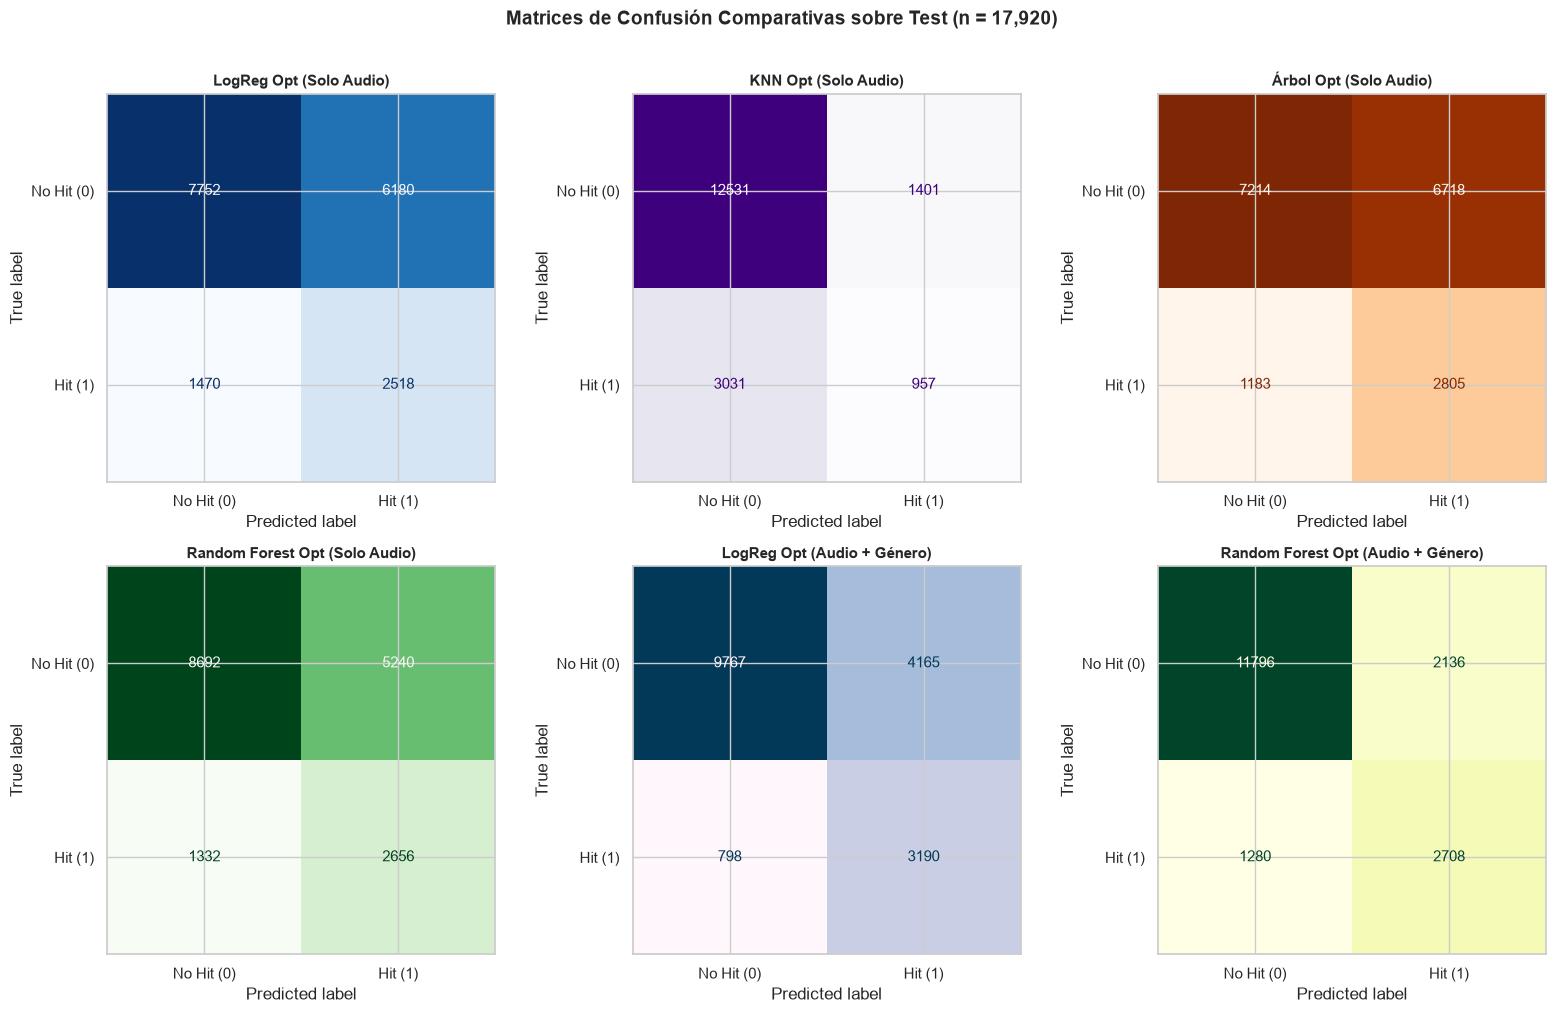

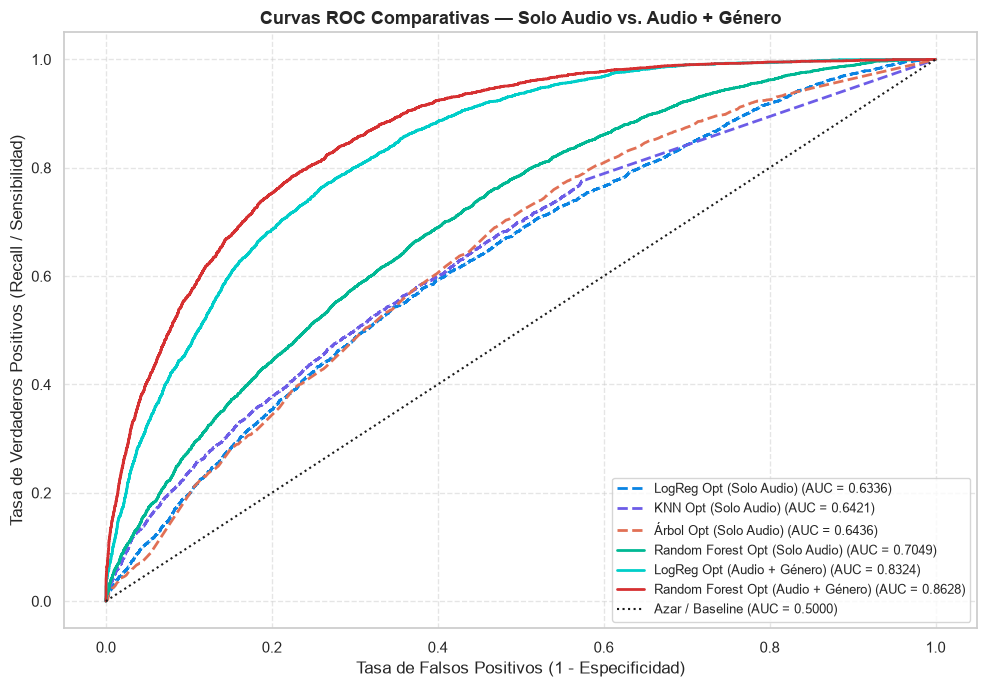

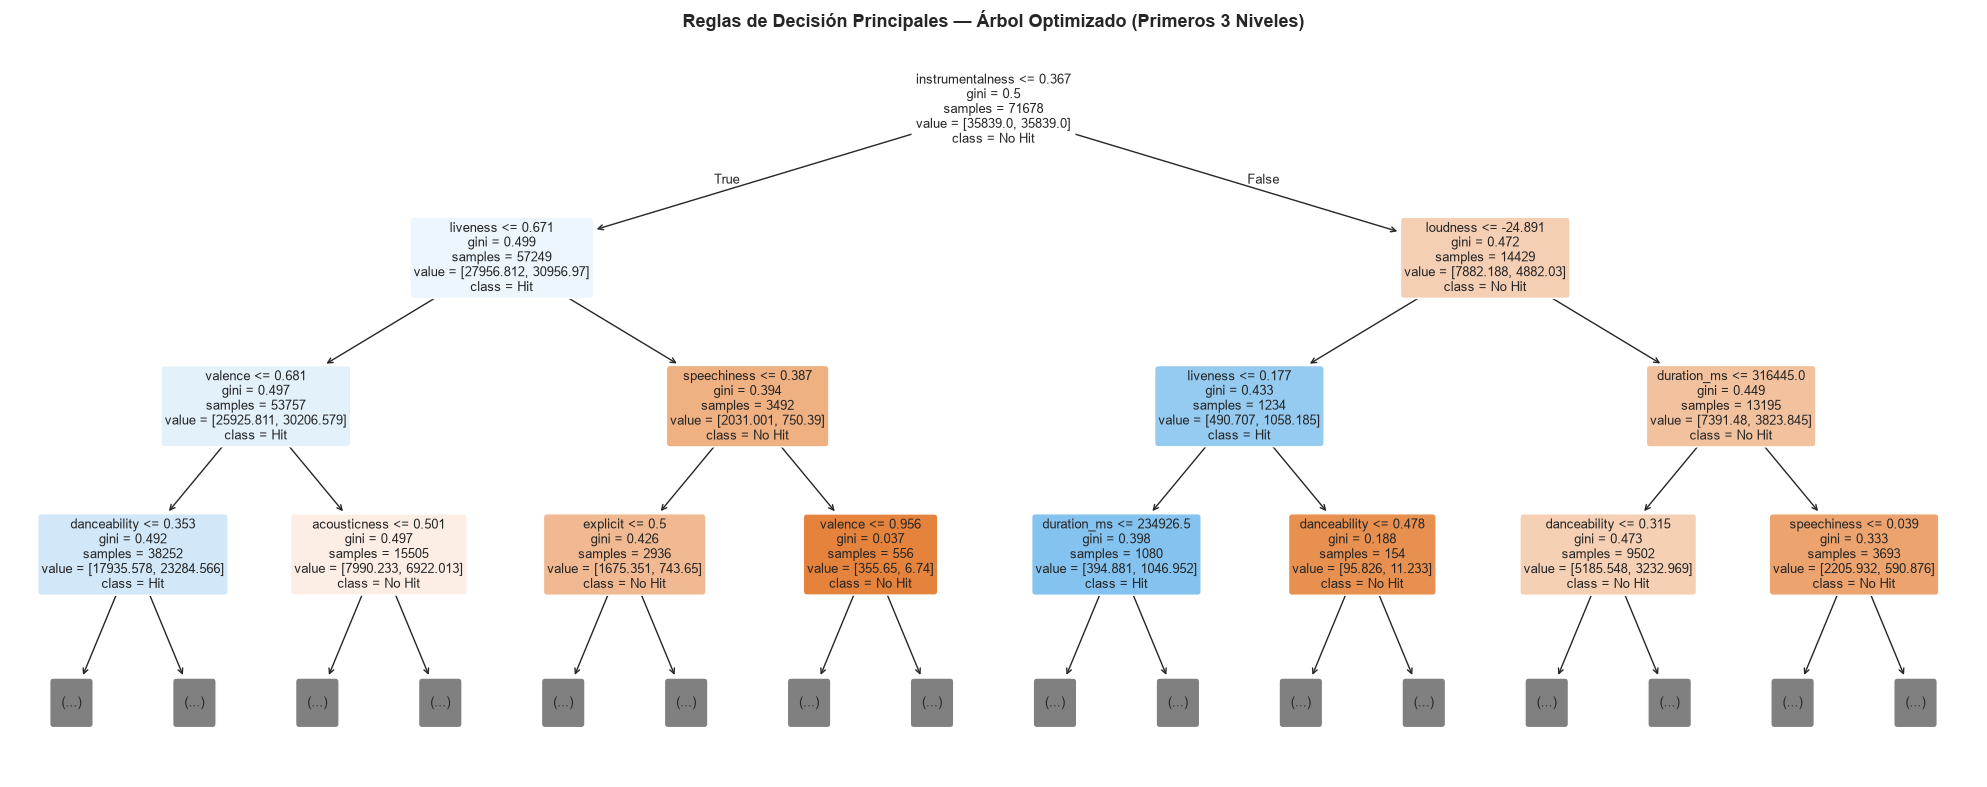

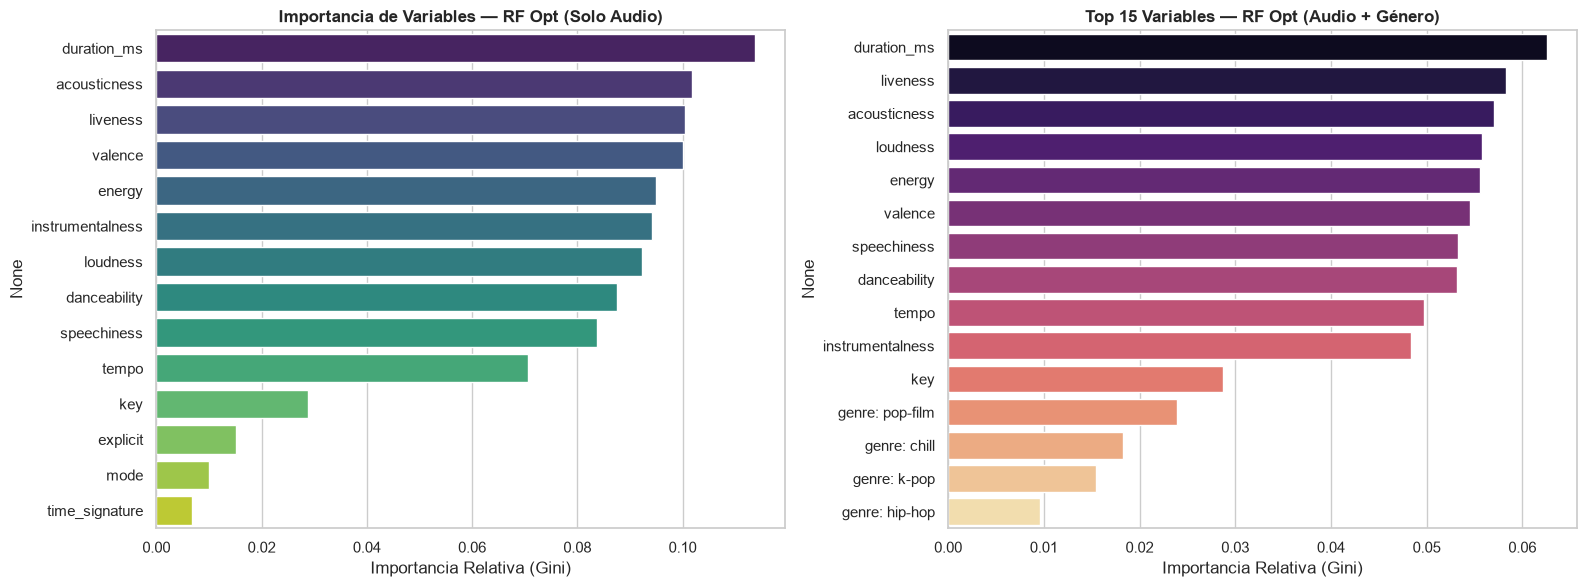

Top 5 features Solo Audio:


duration_ms     0.1138
acousticness    0.1017
liveness        0.1005
valence         0.1001
energy          0.0949
dtype: float64

Top 10 features Audio + Género:


duration_ms         0.0626
liveness            0.0582
acousticness        0.0570
loudness            0.0558
energy              0.0556
valence             0.0545
speechiness         0.0533
danceability        0.0531
tempo               0.0497
instrumentalness    0.0484
dtype: float64

In [18]:
# =============================================================================
# 12.1 MATRICES DE CONFUSIÓN, CURVAS ROC-AUC, ÁRBOL E IMPORTANCIA DE VARIABLES
# =============================================================================

# 1. Matrices de Confusión Comparativas (2 filas x 3 columnas)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

modelos_cm = [
    ("LogReg Opt (Solo Audio)", mejor_log, X_test, "Blues"),
    ("KNN Opt (Solo Audio)", mejor_knn, X_test, "Purples"),
    ("Árbol Opt (Solo Audio)", mejor_arbol, X_test, "Oranges"),
    ("Random Forest Opt (Solo Audio)", mejor_rf, X_test, "Greens"),
    ("LogReg Opt (Audio + Género)", mejor_log_gen, X_test_gen, "PuBu"),
    ("Random Forest Opt (Audio + Género)", mejor_rf_gen, X_test_gen, "YlGn")
]

for ax, (titulo, mod, X_ev, cmap) in zip(axes, modelos_cm):
    cm = confusion_matrix(y_test, mod.predict(X_ev))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Hit (0)", "Hit (1)"])
    disp.plot(ax=ax, cmap=cmap, colorbar=False, values_format="d")
    ax.set_title(titulo, fontsize=11, fontweight="bold")

plt.suptitle("Matrices de Confusión Comparativas sobre Test (n = {:,})".format(len(y_test)), fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# 2. Curvas ROC-AUC Superpuestas
plt.figure(figsize=(10, 7))
curvas = [
    ("LogReg Opt (Solo Audio)", mejor_log, X_test, "#0984e3", "--"),
    ("KNN Opt (Solo Audio)", mejor_knn, X_test, "#6c5ce7", "--"),
    ("Árbol Opt (Solo Audio)", mejor_arbol, X_test, "#e17055", "--"),
    ("Random Forest Opt (Solo Audio)", mejor_rf, X_test, "#00b894", "-"),
    ("LogReg Opt (Audio + Género)", mejor_log_gen, X_test_gen, "#00cec9", "-"),
    ("Random Forest Opt (Audio + Género)", mejor_rf_gen, X_test_gen, "#d63031", "-")
]

for label_m, mod, X_ev, color, ls in curvas:
    proba = mod.predict_proba(X_ev)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{label_m} (AUC = {auc_val:.4f})", color=color, linestyle=ls, linewidth=2)

plt.plot([0, 1], [0, 1], "k:", label="Azar / Baseline (AUC = 0.5000)")
plt.title("Curvas ROC Comparativas — Solo Audio vs. Audio + Género", fontsize=13, fontweight="bold")
plt.xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
plt.ylabel("Tasa de Verdaderos Positivos (Recall / Sensibilidad)")
plt.legend(loc="lower right", fontsize=9.5)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Primeros 3 niveles del Árbol de Decisión Optimizado (Solo Audio)
plt.figure(figsize=(20, 8))
plot_tree(
    mejor_arbol,
    feature_names=X_train.columns,
    class_names=["No Hit", "Hit"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title("Reglas de Decisión Principales — Árbol Optimizado (Primeros 3 Niveles)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# 4. Top 15 Variables Más Influyentes: Random Forest Solo Audio vs Audio + Género
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

imp_audio = pd.Series(mejor_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(14)
sns.barplot(x=imp_audio.values, y=imp_audio.index, hue=imp_audio.index, ax=axes[0], palette="viridis", legend=False)
axes[0].set_title("Importancia de Variables — RF Opt (Solo Audio)", fontweight="bold")
axes[0].set_xlabel("Importancia Relativa (Gini)")

nombres_feat_gen = [
    n.replace("num__", "").replace("cat__track_genre_", "genre: ")
    for n in mejor_rf_gen.named_steps["prep"].get_feature_names_out()
]
imp_gen = pd.Series(mejor_rf_gen.named_steps["clf"].feature_importances_, index=nombres_feat_gen).sort_values(ascending=False).head(15)
sns.barplot(x=imp_gen.values, y=imp_gen.index, hue=imp_gen.index, ax=axes[1], palette="magma", legend=False)
axes[1].set_title("Top 15 Variables — RF Opt (Audio + Género)", fontweight="bold")
axes[1].set_xlabel("Importancia Relativa (Gini)")

plt.tight_layout()
plt.show()

print("Top 5 features Solo Audio:")
display(imp_audio.head(5).round(4))
print("Top 10 features Audio + Género:")
display(imp_gen.head(10).round(4))

In [19]:
# =============================================================================
# 12.2 ANÁLISIS DE ACIERTOS Y ERRORES SOBRE CANCIONES REALES DE TEST
# =============================================================================
df_errores = df_limpio.loc[X_test.index, ["artists", "track_name", "track_genre", "popularity", "is_hit"]].copy()
df_errores["prediccion"] = y_pred_ganador
df_errores["prob_hit"] = np.round(y_proba_ganador, 4)

tn, fp, fn, tp = confusion_matrix(df_errores["is_hit"], df_errores["prediccion"]).ravel()
total_test = len(df_errores)

print(f"=== DESGLOSE DE RESULTADOS EN TEST — {nombre_ganador} ===")
print(f"Verdaderos Negativos (TN - No Hit bien clasificados): {tn:,} ({tn/total_test*100:.2f}%)")
print(f"Verdaderos Positivos (TP - Hits bien detectados):     {tp:,} ({tp/total_test*100:.2f}%)")
print(f"Falsos Positivos     (FP - Falsas alarmas):           {fp:,} ({fp/total_test*100:.2f}%)")
print(f"Falsos Negativos     (FN - Hits omitidos):            {fn:,} ({fn/total_test*100:.2f}%)")

print("\n--- 1. TOP 5 VERDADEROS POSITIVOS (Hits reales detectados con mayor confianza) ---")
display(df_errores[(df_errores["is_hit"] == 1) & (df_errores["prediccion"] == 1)]
        .sort_values("prob_hit", ascending=False).head(5))

print("\n--- 2. TOP 5 FALSOS POSITIVOS (Perfil acústico/género de Hit, pero popularidad <= 50) ---")
display(df_errores[(df_errores["is_hit"] == 0) & (df_errores["prediccion"] == 1)]
        .sort_values("prob_hit", ascending=False).head(5))

print("\n--- 3. TOP 5 FALSOS NEGATIVOS (Hits muy populares no detectados por el modelo) ---")
display(df_errores[(df_errores["is_hit"] == 1) & (df_errores["prediccion"] == 0)]
        .sort_values("popularity", ascending=False).head(5))

print("\n--- GÉNEROS CON MAYOR PROPORCIÓN DE ERRORES EN TEST (top 8 por volumen >= 40 pistas) ---")
df_errores["acierto"] = (df_errores["is_hit"] == df_errores["prediccion"]).astype(int)
resumen_gen = df_errores.groupby("track_genre").agg(
    canciones=("acierto", "count"),
    tasa_hits_real=("is_hit", "mean"),
    accuracy_local=("acierto", "mean")
).query("canciones >= 40").sort_values("accuracy_local", ascending=True)
resumen_gen["tasa_hits_%"] = (resumen_gen["tasa_hits_real"] * 100).round(2)
resumen_gen["accuracy_%"] = (resumen_gen["accuracy_local"] * 100).round(2)
display(resumen_gen[["canciones", "tasa_hits_%", "accuracy_%"]].head(8))

=== DESGLOSE DE RESULTADOS EN TEST — 6. Random Forest (Opt - Audio+Género) ===
Verdaderos Negativos (TN - No Hit bien clasificados): 11,796 (65.83%)
Verdaderos Positivos (TP - Hits bien detectados):     2,708 (15.11%)
Falsos Positivos     (FP - Falsas alarmas):           2,136 (11.92%)
Falsos Negativos     (FN - Hits omitidos):            1,280 (7.14%)

--- 1. TOP 5 VERDADEROS POSITIVOS (Hits reales detectados con mayor confianza) ---


,artists,track_name,track_genre,popularity,is_hit,prediccion,prob_hit
65956,TAEIL,Starlight,k-pop,62,1,1,0.9986
80984,Rahat Fateh Ali Khan;Nish Asher,Khuda Aur Mohabbat (Original Score),pop-film,57,1,1,0.9985
80515,A.R. Rahman;Mohit Chauhan,Nadaan Parinde,pop-film,60,1,1,0.9984
65620,TWICE,SCIENTIST,k-pop,71,1,1,0.9984
80400,Javed Ali,Guzarish,pop-film,62,1,1,0.9984



--- 2. TOP 5 FALSOS POSITIVOS (Perfil acústico/género de Hit, pero popularidad <= 50) ---


,artists,track_name,track_genre,popularity,is_hit,prediccion,prob_hit
80554,Rahat Fateh Ali Khan,Qalandar (Original Score),pop-film,33,0,1,0.9980
80373,Vishal-Shekhar;Snigdhajit Bhowmik;Ananya Chakr...,Alcoholia,pop-film,40,0,1,0.9979
15862,Anthony Russo,Nobody To Love,chill,49,0,1,0.9816
44908,Audioslave,Shadow on the Sun,grunge,28,0,1,0.9690
83293,Armin van Buuren;The Stickmen Project,No Fun,progressive-house,0,0,1,0.9669



--- 3. TOP 5 FALSOS NEGATIVOS (Hits muy populares no detectados por el modelo) ---


,artists,track_name,track_genre,popularity,is_hit,prediccion,prob_hit
67603,Bad Bunny,Moscow Mule,latin,94,1,0,0.4917
20017,Charlie Puth;Jung Kook;BTS,Left and Right (Feat. Jung Kook of BTS),dance,92,1,0,0.3834
67602,Shakira;Rauw Alejandro,Te Felicito,latin,90,1,0,0.2405
20811,James Hype;Miggy Dela Rosa,Ferrari,dance,90,1,0,0.3510
3300,Oliver Tree;Robin Schulz,Miss You,alternative,87,1,0,0.3045



--- GÉNEROS CON MAYOR PROPORCIÓN DE ERRORES EN TEST (top 8 por volumen >= 40 pistas) ---


,canciones,tasa_hits_%,accuracy_%
track_genre,,,
mandopop,186,40.86,50.54
synth-pop,172,27.33,51.74
indian,154,40.26,52.60
metalcore,151,45.03,54.30
electronic,156,33.33,54.49
acoustic,216,41.67,54.63
dancehall,205,31.71,55.12
ambient,215,48.37,55.81


### 🔍 Interpretación de Visualizaciones, Variables Clave y Causas de Error
1. **Balance de la Matriz de Confusión (`Random Forest Opt - Audio+Género` sobre `17,920` pistas de Test):**
   - **Verdaderos Negativos (`TN = 11,796` | `65.83%`):** Correctamente filtradas como catálogo no masivo.
   - **Verdaderos Positivos (`TP = 2,708` | `15.11%`):** Hits reales capturados con éxito (en particular nichos de alta densidad comercial como `k-pop` — *TAEIL - Starlight* `prob=0.9986`, *TWICE - SCIENTIST* `prob=0.9984` — y `pop-film`).
   - **Falsos Positivos (`FP = 2,136` | `11.92%`):** Canciones cuyo perfil sonoro y género coinciden con un Hit (ej. *Audioslave - Shadow on the Sun* en `grunge`, `prob=0.9690`; *Armin van Buuren - No Fun* en `progressive-house`, `prob=0.9669` pero con `popularity=0` por indexación/reediciones en Spotify).
   - **Falsos Negativos (`FN = 1,280` | `7.14%`):** Mega-éxitos que el modelo no logra capturar a partir del audio y género porque responden a **factores exógenos no observables en el CSV** (fama previa del artista, campañas globales, viralidad en redes y colaboraciones). Casos emblemáticos observados en Test: *Bad Bunny - Moscow Mule* (`latin`, `pop=94`, `prob_hit=0.4917`, justo debajo del umbral `0.50`), *Charlie Puth; Jung Kook; BTS - Left and Right* (`dance`, `pop=92`, `prob=0.3834`) y *Shakira; Rauw Alejandro - Te Felicito* (`latin`, `pop=90`, `prob=0.2405`).
2. **Curvas ROC-AUC e Importancia de Variables:** Las curvas ROC confirman la separación en tres escalones claros (`~0.63-0.64` lineales/KNN/árbol solo audio → `0.7049` Random Forest solo audio → **`0.8324` / `0.8628`** al incorporar `track_genre`). En Random Forest, las variables continuas (`duration_ms`, `liveness`, `acousticness`, `loudness`, `energy`, `valence`) lideran los cortes finos dentro de cada género, mientras las 113 dummies de género aportan el contexto estructural de popularidad.
3. **Géneros más desafiantes:** Subgéneros heterogéneos donde conviven lanzamientos independientes y éxitos masivos bajo rasgos acústicos similares registran menor accuracy local (`mandopop` `50.54%`, `synth-pop` `51.74%`, `indian` `52.60%`, `metalcore` `54.30%`).

## 13. Bonus: Segmentación Acústica No Supervisada con K-Means (Clase 11)

Complementando el modelado supervisado y aplicando lo trabajado en la **Clase 11 (Clustering con K-Means)**, agrupamos el catálogo de entrenamiento exclusivamente a partir de sus **9 métricas continuas de audio** (sin utilizar `is_hit` ni `track_genre`) para descubrir "vibras" o perfiles sonoros naturales y auditar qué porcentaje de *Hits* concentra cada segmento.

,k,Inercia,Silhouette (muestra 5k)
0,2,23763.68,0.3069
1,3,19172.46,0.2908
2,4,15874.22,0.3175
3,5,13794.90,0.2540
4,6,12559.36,0.2630
5,7,11599.82,0.2362
6,8,10928.42,0.2287


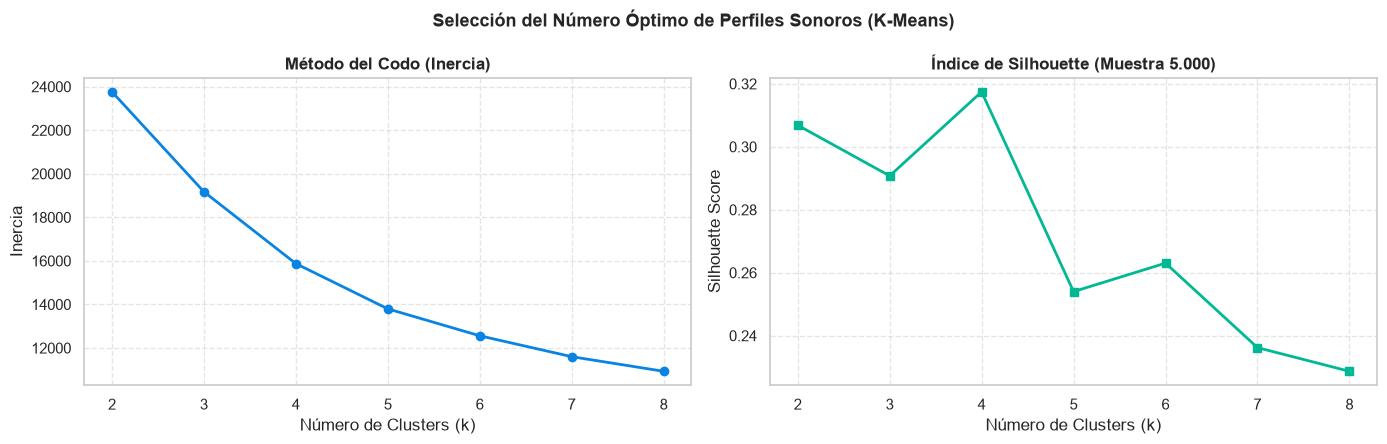


=== PERFIL ACÚSTICO PROMEDIO POR CLUSTER (ESCALA 0-1) Y TASA DE HITS ===


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,Tasa_Hits (%),Cantidad_Canciones
Cluster,,,,,,,,,,,
0,0.567,0.768,0.761,0.078,0.072,0.764,0.202,0.339,0.523,11.987,8743
1,0.605,0.768,0.805,0.095,0.118,0.019,0.225,0.543,0.520,25.609,37873
2,0.401,0.211,0.555,0.056,0.867,0.846,0.158,0.225,0.435,19.841,5519
3,0.556,0.438,0.728,0.099,0.702,0.017,0.228,0.465,0.475,21.031,19543


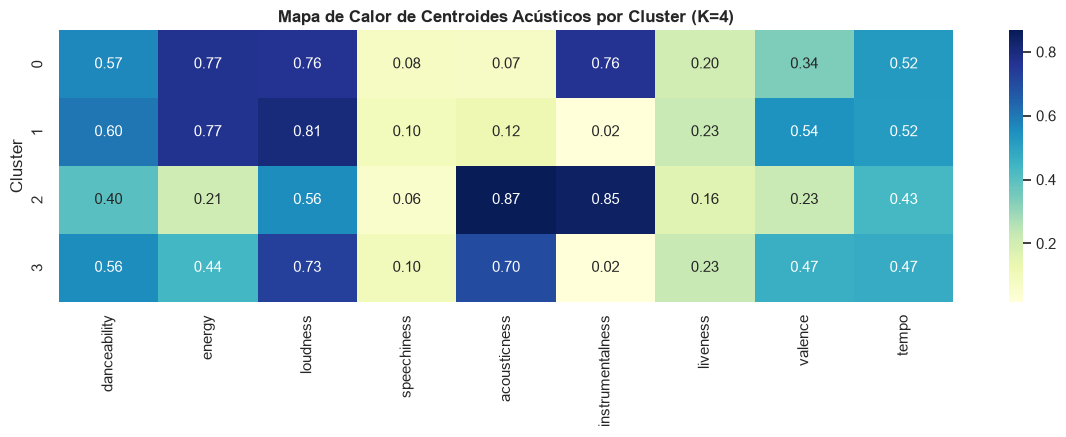

In [20]:
# =============================================================================
# 13.1 CLUSTERING NO SUPERVISADO (K-MEANS + MÉTODO DEL CODO + SILHOUETTE)
# =============================================================================
features_audio_km = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo"
]

# Escalamos al rango [0, 1] ajustando únicamente con X_train
scaler_km = MinMaxScaler()
X_audio_train = scaler_km.fit_transform(X_train[features_audio_km])

inercias = []
silhouettes = []
rango_k = range(2, 9)

for k in rango_k:
    km_tmp = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_tmp = km_tmp.fit_predict(X_audio_train)
    inercias.append(km_tmp.inertia_)
    sil = silhouette_score(X_audio_train, etiquetas_tmp, sample_size=5000, random_state=42)
    silhouettes.append(sil)

df_k_eval = pd.DataFrame({"k": list(rango_k), "Inercia": np.round(inercias, 2), "Silhouette (muestra 5k)": np.round(silhouettes, 4)})
display(df_k_eval)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(list(rango_k), inercias, marker="o", color="#0984e3", linewidth=2)
axes[0].set_title("Método del Codo (Inercia)", fontweight="bold")
axes[0].set_xlabel("Número de Clusters (k)")
axes[0].set_ylabel("Inercia")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(list(rango_k), silhouettes, marker="s", color="#00b894", linewidth=2)
axes[1].set_title("Índice de Silhouette (Muestra 5.000)", fontweight="bold")
axes[1].set_xlabel("Número de Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Selección del Número Óptimo de Perfiles Sonoros (K-Means)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Entrenamos K-Means con k = 4 segmentos musicales interpretables
K_OPTIMO = 4
kmeans_final = KMeans(n_clusters=K_OPTIMO, random_state=42, n_init=10)
clusters_train = kmeans_final.fit_predict(X_audio_train)

df_clusters = pd.DataFrame(X_audio_train, columns=features_audio_km)
df_clusters["Cluster"] = clusters_train
df_clusters["Tasa_Hits (%)"] = y_train.values * 100

perfil_clusters = df_clusters.groupby("Cluster").mean().round(3)
perfil_clusters["Cantidad_Canciones"] = df_clusters["Cluster"].value_counts().sort_index()

print("\n=== PERFIL ACÚSTICO PROMEDIO POR CLUSTER (ESCALA 0-1) Y TASA DE HITS ===")
display(perfil_clusters)

plt.figure(figsize=(12, 4.5))
sns.heatmap(perfil_clusters[features_audio_km], annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Mapa de Calor de Centroides Acústicos por Cluster (K=4)", fontweight="bold")
plt.tight_layout()
plt.show()

### 🎧 Bautismo Comercial y Lectura de Negocio de los Clusters
El Índice de Silhouette sobre muestra de `5,000` canciones alcanza su **máximo global en `k = 4` (`0.3175`, inercia `15,874.22`)**, coincidiendo con el codo de la curva. Al auditar los centroides normalizados `[0, 1]` de las `71,678` canciones de entrenamiento emergen cuatro "vibras" claramente diferenciadas:

| Cluster | Canciones | Tasa de Hits (%) | Perfil Acústico Dominante | Nombre Comercial de Playlist |
| :---: | :---: | :---: | :--- | :--- |
| **0** | `8,743` | **11.99%** | Alta `energy` (`0.768`), alta `instrumentalness` (`0.764`), mínima `acousticness` (`0.072`) | **⚡ Electrónica & Rock Instrumental Intenso** |
| **1** | `37,873` | **25.61%** | Máxima `danceability` (`0.605`), `loudness` (`0.805`) y `valence` (`0.543`); baja `instrumentalness` (`0.019`) | **🔥 Mainstream Pop, Dance & Urbano Comercial** |
| **2** | `5,519` | **19.84%** | Máxima `acousticness` (`0.867`) e `instrumentalness` (`0.846`); mínima `energy` (`0.211`) | **🎹 Focus Profundo, Clásica & Ambient** |
| **3** | `19,543` | **21.03%** | Alta `acousticness` (`0.702`), vocal (`instrumentalness = 0.017`), `energy` moderada (`0.438`) | **☕ Acústico Vocal, Indie & Baladas Chill** |

**Hallazgo clave:** Sin haber visto nunca la variable objetivo `is_hit`, **K-Means** aisló en el **Cluster 1** el nicho comercial por excelencia: concentra el **52.8%** de las pistas de entrenamiento y más del **doble de tasa de Hits (`25.61%`)** que el Cluster 0 puramente instrumental energético (`11.99%`).

## 14. Conclusiones Estratégicas y Anexo Final (B6 y B7)

### 14.1 Conclusiones del Proyecto (B6)
1. **Reflexión sobre el Modelo Ganador:** La continuidad metodológica desde la Pre-Entrega permitió validar que el éxito comercial en Spotify depende de interacciones no lineales entre atributos sonoros y ecosistema de género. **Random Forest optimizado con `ColumnTransformer` (Audio + Género)** alcanzó **`ROC-AUC = 0.8628`**, **`F1-Score = 0.6132`**, **`Accuracy = 0.8094`** y altísima estabilidad en 5 folds (`F1 CV = 0.6106 ± 0.0040`), superando en **+0.1662** puntos de F1 a su equivalente solo acústico.
2. **Costo de Errores y Aplicación Práctica:**
   - Para **curadores de playlists y cazatalentos (A&R)**, los Falsos Negativos (`1,280`) implican dejar pasar un Hit potencial (como *Bad Bunny - Moscow Mule* que obtuvo `prob_hit = 0.4917`). Por ello, en entornos reales conviene calibrar el umbral de decisión por debajo de `0.50` (p. ej. `0.40`) o utilizar **`Regresión Logística (Audio+Género)`** cuando se priorice máxima cobertura (`Recall = 0.7999`).
   - Los Falsos Positivos (`2,136`) funcionan en la práctica como un **radar de "joyas ocultas"**: canciones con la receta acústica y de género de un éxito que aún no tuvieron exposición.
3. **Límites del Modelo:** Ningún atributo de audio mide variables exógenas determinantes como la fama previa del artista, presupuesto promocional, viralidad en TikTok/Reels ni artefactos de indexación del catálogo (tracks populares reeditados que aparecen con `popularity = 0`).
4. **Posibilidades de Mejora:** Incorporar algoritmos de *Gradient Boosting* (`LightGBM` / `XGBoost`), ajustar el umbral de probabilidad (*threshold tuning*) según el costo de negocio, sumar historial del artista sin fuga temporal y analizar datos líricos o espectrogramas de audio.

---

### 14.2 Anexo Final (B7)
- **Dataset original en Kaggle:** [Spotify Tracks Dataset — Maharshi Pandya](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset)
- **Carpeta de Entrega Final en Google Drive:** [HERNANDEZ MATIAS H - Comisión 26240 - TPI Machine Learning](https://drive.google.com/drive/folders/1qlKrshYD_2ZqjH_gToYyP0Jt4nvjdiUT)
- **Dataset original (`dataset.csv`) en Google Drive:** [Ver archivo en Drive](https://drive.google.com/file/d/1D-hpD1zvoAng0lD9Mci4_jXukBtS_G17/view?usp=drivesdk)
- **Informe técnico ejecutivo (`informe_final.md`) en Google Drive:** [Ver informe en Drive](https://docs.google.com/document/d/1kmaUo-ZMdGkDZcC9Vv9GbBipCuW200gZ/edit?usp=drivesdk&ouid=104235964126440859306&rtpof=true&sd=true)
- **Repositorio GitHub del proyecto:** [tutecoach/talento-tech-ml](https://github.com/tutecoach/talento-tech-ml)
- **Referencias técnicas utilizadas:**
  - Documentación oficial de *Scikit-Learn* (`Pipeline`, `ColumnTransformer`, `StratifiedKFold`, `GridSearchCV`, `LogisticRegression`, `KNeighborsClassifier`, `DecisionTreeClassifier`, `RandomForestClassifier`, `KMeans`).
  - Documentación de *Pandas*, *NumPy*, *Matplotlib* y *Seaborn*.
  - Material teórico y práctico de las Clases 01 a 16 — Talento Tech Machine Learning (Comisión #26240).
- **Aclaraciones metodológicas:**
  - Este cuaderno continúa directamente la estructura de la Pre-Entrega (`Pre_entrega26.ipynb`).
  - En la celda `4.1` se incorporó el descarte explícito de la columna índice `'Unnamed: 0'` para evitar fuga por ordenamiento de filas.
  - Todas las transformaciones (`StandardScaler`, `OneHotEncoder`, `MinMaxScaler`) se ajustaron estrictamente sobre el conjunto de entrenamiento (`fit` solo en `Train`).
  - Cuaderno ejecutado íntegramente de principio a fin sin errores.